In [1]:
import numpy as np
import pandas as pd
import sympy
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
import matplotlib.cm as cm
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky
from numpy.random import multivariate_normal
from sympy import symbols, diff
from scipy.interpolate import PchipInterpolator
from scipy.optimize import curve_fit

from scipy.integrate import quad, dblquad
from scipy.interpolate import interp1d
from scipy import interpolate
from scipy.interpolate import UnivariateSpline
from scipy.interpolate import CubicSpline

import os
import seaborn as sns
import pandas as pd

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams["figure.figsize"] = [15,10]
plt.rcParams["font.size"] = 30

In [2]:
#units
MeV_to_fm_m1 = 1/197.3
GeV_to_fm = 5.068
MeV_to_GeV = 1e-3
hbarc = 197.3 # MeV fm
MeV4_to_GeV_fm3 = (MeV_to_GeV**4)*GeV_to_fm**3

## Reading in lattice data

In [3]:
data = pd.read_csv("cs2_WB.dat",sep=r"\s+",header=None)
data_extracted = pd.read_csv("./cs2_data_extrap/points_extracted",sep=",",header=None)

In [4]:
lat_cs2 = data[[0,1,2]]
extract_cs2 = data_extracted[[0,1]]

In [5]:
lat_cs2.columns = ['T','cs2','error']
extract_cs2.columns = ['T_extract', 'cs2_extract']

In [6]:
# ax = plt.subplot()

# # Lattice mean
# ax.plot(lat_cs2['T'], lat_cs2['cs2'],c = 'black',ms='10',lw=5)
# #Lattice error

# gray_with_alpha = to_rgba('gray', 0.3)

# ax.fill_between(
#     lat_cs2['T'],
#     lat_cs2['cs2'] - lat_cs2['error'],
#     lat_cs2['cs2'] + lat_cs2['error'],
#     facecolor=gray_with_alpha,
#     label='WB (2025)'
# )

# ax.set_xlabel("T [MeV]")
# ax.set_ylabel(r"$c_s^2$")
   
# ax.patch.set_edgecolor('black')  
# ax.patch.set_linewidth('5') 
# ax.xaxis.set_tick_params(width=5,length=10) 
# ax.yaxis.set_tick_params(width=5,length=10)
# ax.yaxis.major.formatter._useMathText = True


# ax.legend(loc='lower right',framealpha = 0, 
#            frameon=False,fontsize=30,ncol=2)


In [6]:
lat_cs2.to_csv("data.dat", sep= ' ', index = False)
extract_cs2.to_csv("data_extracted.dat", sep= ',', index = False)

extract_cs2_interp = interp1d(extract_cs2['T_extract'], extract_cs2['cs2_extract'], kind='linear') 

## GPs

In [7]:
def cs2fromphi(element):
    return 1/(np.exp(element) +1)

def phifromsc2(element):
    return np.log(1/element - 1)

In [8]:
def kernel_func(x1,x2,sigma,l):
    return(sigma*np.exp(-(x1-x2)**2/(2*l**2)))

In [9]:
#temperature vectors with stepsize one

T_sampling = np.linspace(120,700,700-120+1)
T_sampling_up = np.linspace(261,700,700-261+1)

GP_mean_file = lat_cs2.cs2
GP_mean_extract = extract_cs2_interp(T_sampling_up)

In [ ]:
## GP hyperparameters ##
##################
l = 15
sigma = 0.03
##################

In [155]:
mean_data = np.concatenate([GP_mean_file, GP_mean_extract])

def generate_sample():   
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_sampling:
        k_row = []
        for x2 in T_sampling:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

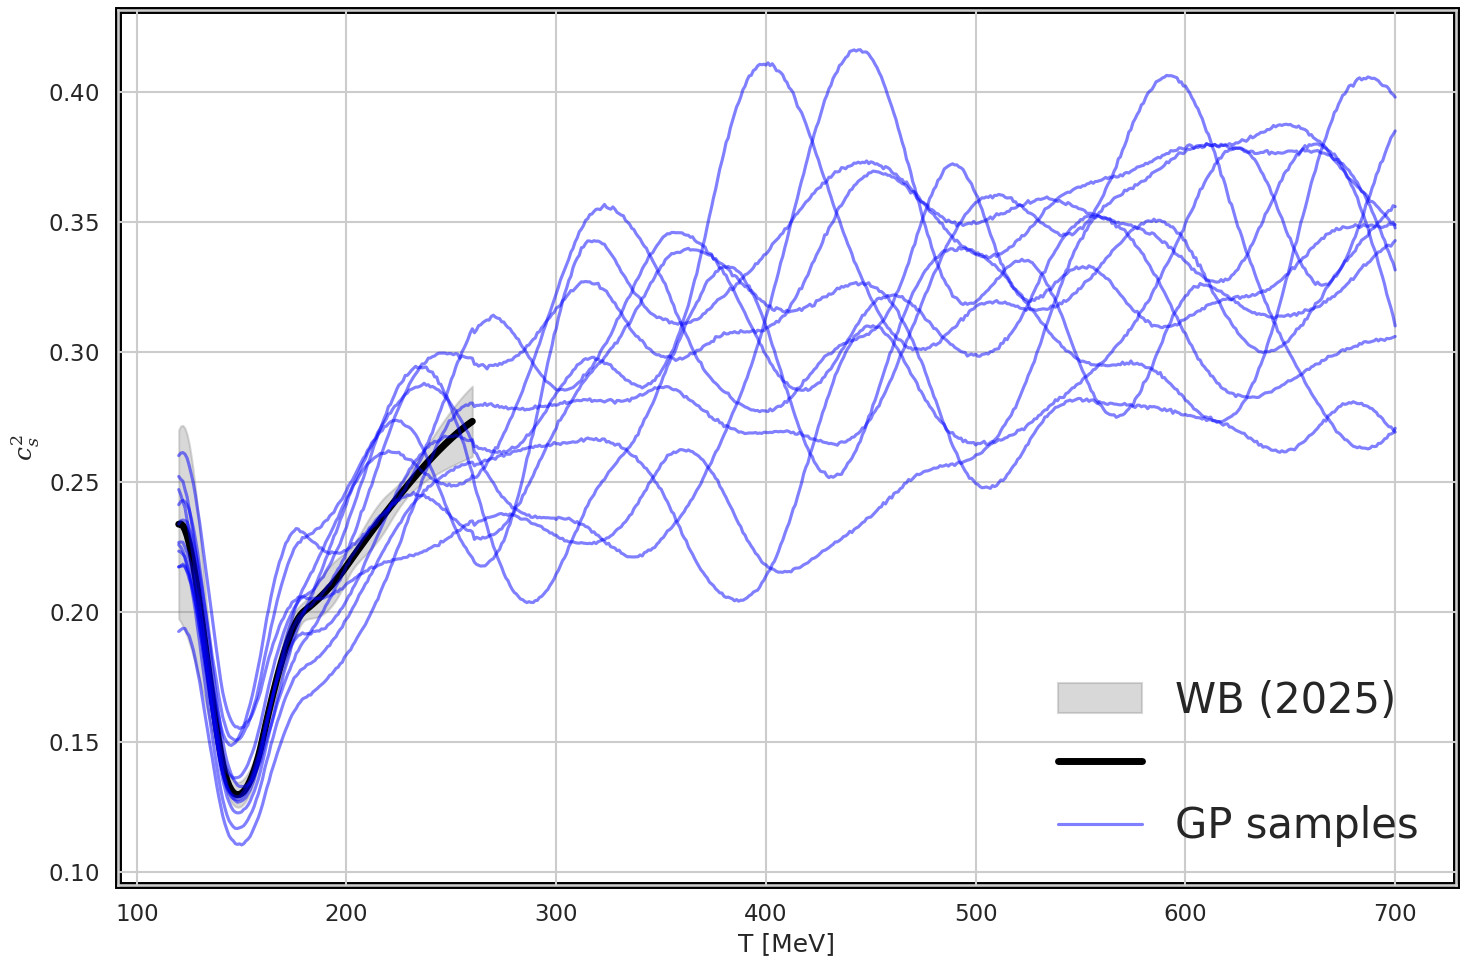

In [14]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lat_cs2['T'],
    lat_cs2['cs2'] - lat_cs2['error'],
    lat_cs2['cs2'] + lat_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data=lat_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    cs2_sample = generate_sample()
    
    ax.plot(
        T_sampling,
        cs2_sample,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2.png')
plt.show()



## HRG

In [16]:
file_path = "./pdg-urqmd_v3.3+.dat"

if not os.path.isfile(file_path):
    print("Unable to open file")
    exit(1)

m_bosons = []
m_fermions = []
g_b = []
g_f = []

with open(file_path, "r") as file:
    for line in file:
        
        #removes whitespace characters, including spaces, tabs, and newlines
        line = line.strip() 
        
        if not line:
            continue  # skip empty lines

        values = line.split()

        if values[1][0].isalpha():
            try:
                mass = float(values[2])
                f_or_b = int(values[5])
                g = float(values[4])
                mass_mev = mass * 1e3  #MeV

                if f_or_b == 1:
                    m_fermions.append(mass_mev)
                    g_f.append(g)
                elif f_or_b == 0:
                    m_bosons.append(mass_mev)
                    g_b.append(g)
            except ValueError:
                continue  
        elif values[1][0].isdigit():
            continue  


In [17]:
def bose_einstein(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    return 1.0/(np.expm1(x))

def fermi_dirac(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    return 1.0/(np.expm1(x) +1 + 1)

def pressure_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(6.0*(np.pi)**2))*(k**4)*fermi_dirac(k, T, mass)/(np.sqrt(k**2 + mass**2))
    elif eta == 0:
        return (g/(6.0*(np.pi)**2))*(k**4)*bose_einstein(k, T, mass)/(np.sqrt(k**2 + mass**2))
    else:
        raise ValueError("eta must be 0 or 1")

def energy_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*fermi_dirac(k, T, mass)
    elif eta == 0:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*bose_einstein(k, T, mass)

In [18]:
T_sw = 150 #MeV

def pressure_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

def energy_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

P_sw = pressure_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
e_sw = energy_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
s_sw =  (P_sw + e_sw)/T_sw #MeV^3

print(P_sw*MeV4_to_GeV_fm3)
print(e_sw*MeV4_to_GeV_fm3)
print(s_sw*(1/hbarc**3))

#print(total_energy(T, m_fermions, g_f, m_bosons, g_b)/T**4)
#print(total_pressure(T, m_fermions, g_f, m_bosons, g_b)/T**4)
#print(entropy/T**3)

0.05252691870421028
0.25324995461914196
2.03902383324895


## Thermodynamics from sample

In [ ]:
cs2_sample_list = generate_sample()

cs2_interp = interp1d(T_sampling, cs2_sample_list)

T_range_up = np.round(np.arange(120, 700 + 0.001, 0.1), 10)
T_range_down = np.round(np.arange(0, 119.9 + 0.001, 0.1), 10)

T_total = np.round(np.arange(0, 700 + 0.001, 0.1), 10)

In [20]:
#s upwards

def s_integrand(T, cs2_interp):
    return 1 / (T * cs2_interp(T))
    
def entropy_up(s_sw, T_sw, cs2_interp, T_range_up):
    s_up = []
        
    for T in T_range_up:
        if T < T_sw:
            integral, _ = quad(s_integrand, T, T_sw, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            s = s_sw * np.exp(-integral)
        elif T > T_sw:
            integral, _ = quad(s_integrand, T_sw, T, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            s = s_sw * np.exp(integral)
        else:
            s = s_sw
        s_up.append(s)
    return s_up

s_up = entropy_up(s_sw, T_sw, cs2_interp, T_range_up)

In [21]:
s_up_interp = interp1d(T_range_up, s_up, kind='linear', fill_value="extrapolate")

In [22]:
#pressure upwards

def P_integrand(T, s_interp):
    return s_interp(T)

def pressure_up(P_sw, T_sw, T_vec, s_interp):
    pressure = []
    for T in T_vec:
        if T < T_sw:
            integral, _ = quad(P_integrand, T, T_sw, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw - integral
        elif T > T_sw:
            integral, _ = quad(P_integrand, T_sw, T, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw + integral
        else:
            p = P_sw
        pressure.append(p)
    return pressure

P_up = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)
P_up_interp = interp1d(T_range_up, P_up, kind='linear', fill_value="extrapolate")

In [23]:
#energy upwards

def energy_up(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))
    return energy_vec

e_up = energy_up(s_up_interp, P_up_interp, T_range_up)

## Downwards extrap using power law

In [24]:
#s_down

def s_extrap_pwr(T, T_range_up, s_up, P_up):
    T0 = T_range_up[0]
    s0 = s_up[0]
    p0 = P_up[0]

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return a_s * T**n

s_pwr_total =  np.concatenate([s_extrap_pwr(T_range_down, T_range_up, s_up, P_up), s_up_interp(T_range_up)])

s_interp_pwr = interp1d(T_total, s_pwr_total, kind='cubic')

sT_vec_pwr = []
for T in T_total:
    sT_vec_pwr.append(s_interp_pwr(T)*T)

In [25]:
#pressure downwards

def P_extrap_pwr(T, T_range_up, s_up, P_up):
    T0 = T_range_up[0]
    s0 = s_up[0]
    p0 = P_up[0]

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return (a_s*T**(n+1))/(n+1) 

P_pwr_total = np.concatenate([P_extrap_pwr(T_range_down, T_range_up, s_up, P_up), P_up])

P_interp_pwr = interp1d(T_total, P_pwr_total)


In [26]:
#energy downwards

e_extrap_pwr = []
for i, T in enumerate(T_range_down):
    s = s_extrap_pwr(T, T_range_up, s_up, P_up)             
    p = P_extrap_pwr(T, T_range_up, s_up, P_up)             
    e = s * T - p             
    e_extrap_pwr.append(e)

e_pwr_total = np.concatenate([e_extrap_pwr, e_up])

e_interp_pwr = interp1d(T_total, e_pwr_total)

In [28]:
with open("./check_files/thermo_check_powerlaw.txt", "w") as f:
    for i, T in enumerate(T_range_down):
        s = s_extrap_pwr(T, T_range_up, s_up, P_up)
        p = P_extrap_pwr(T, T_range_up, s_up, P_up)
        e = e_extrap_pwr[i]

        check = e + p
        expected = s * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")


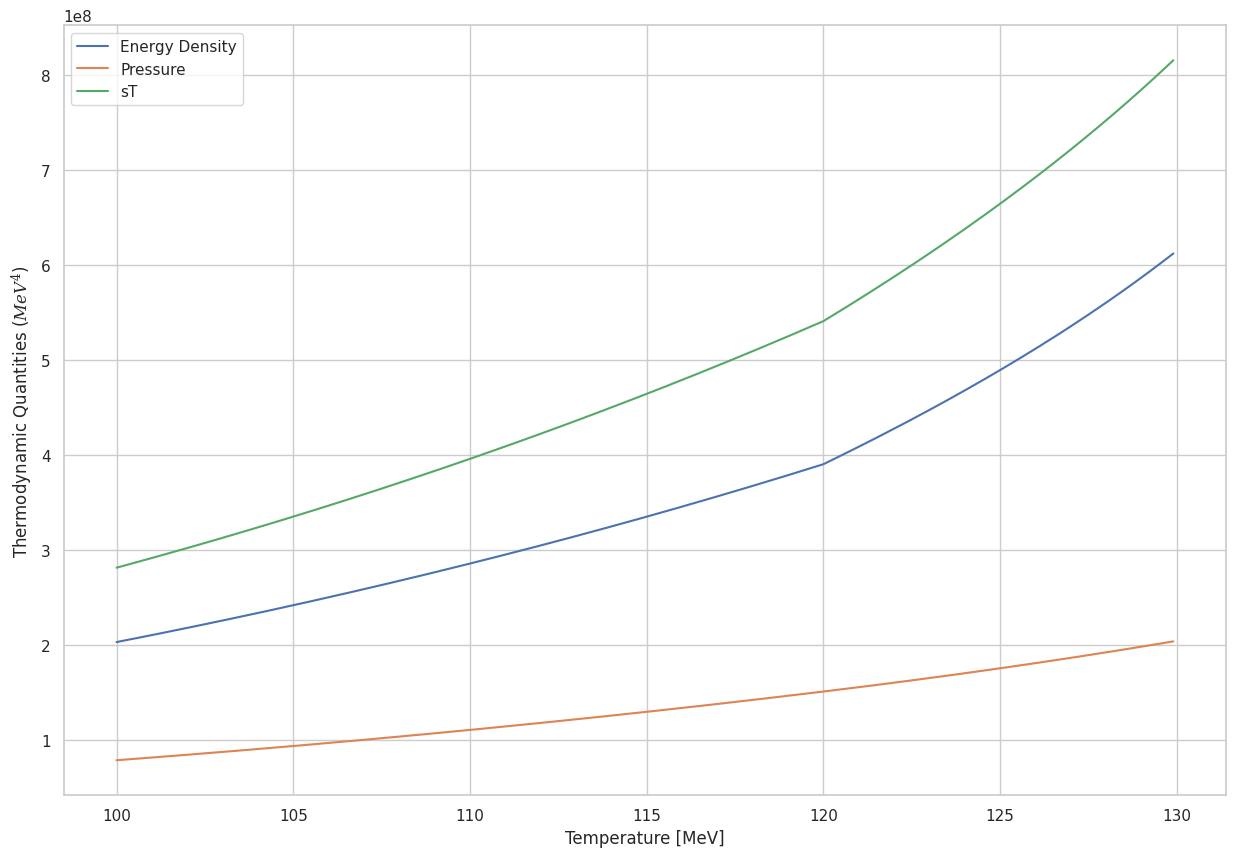

In [29]:
#all thermo plots

df = pd.DataFrame({'T': T_total[1000:1300], 'Entropy': s_pwr_total[1000:1300], 'Energy': e_pwr_total[1000:1300], 
                   'Pressure': P_pwr_total[1000:1300], 'sT': sT_vec_pwr[1000:1300]})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='Energy', label='Energy Density')
sns.lineplot(data=df, x='T', y='Pressure', label='Pressure')
sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities ($ MeV^4$)')
plt.legend()
plt.savefig('./images/power_extrap.png')
plt.show()

In [184]:
#cs2_vector

def cs2_extrap_pwr(T_range_down, T_range_up, s_up, P_up):
    cs2_down = []
    T0 = T_range_up[0]
    s0 = s_up[0]
    p0 = P_up[0]

    n = (T0*s0/p0) - 1

    for T in T_range_down:
        cs2_down.append(1/n)

    return cs2_down
    
cs2_total_pwr = np.concatenate([cs2_extrap_pwr(T_range_down[0:1100], T_range_up, s_up, P_up), cs2_interp(T_range_up)])

T_interp_cs2 = np.concatenate([T_range_down[0:1100], T_range_up])

cs2_interp_pwr = interp1d(T_interp_cs2, cs2_total_pwr, kind='quadratic')


/tmp/ipykernel_16473/2450476379.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


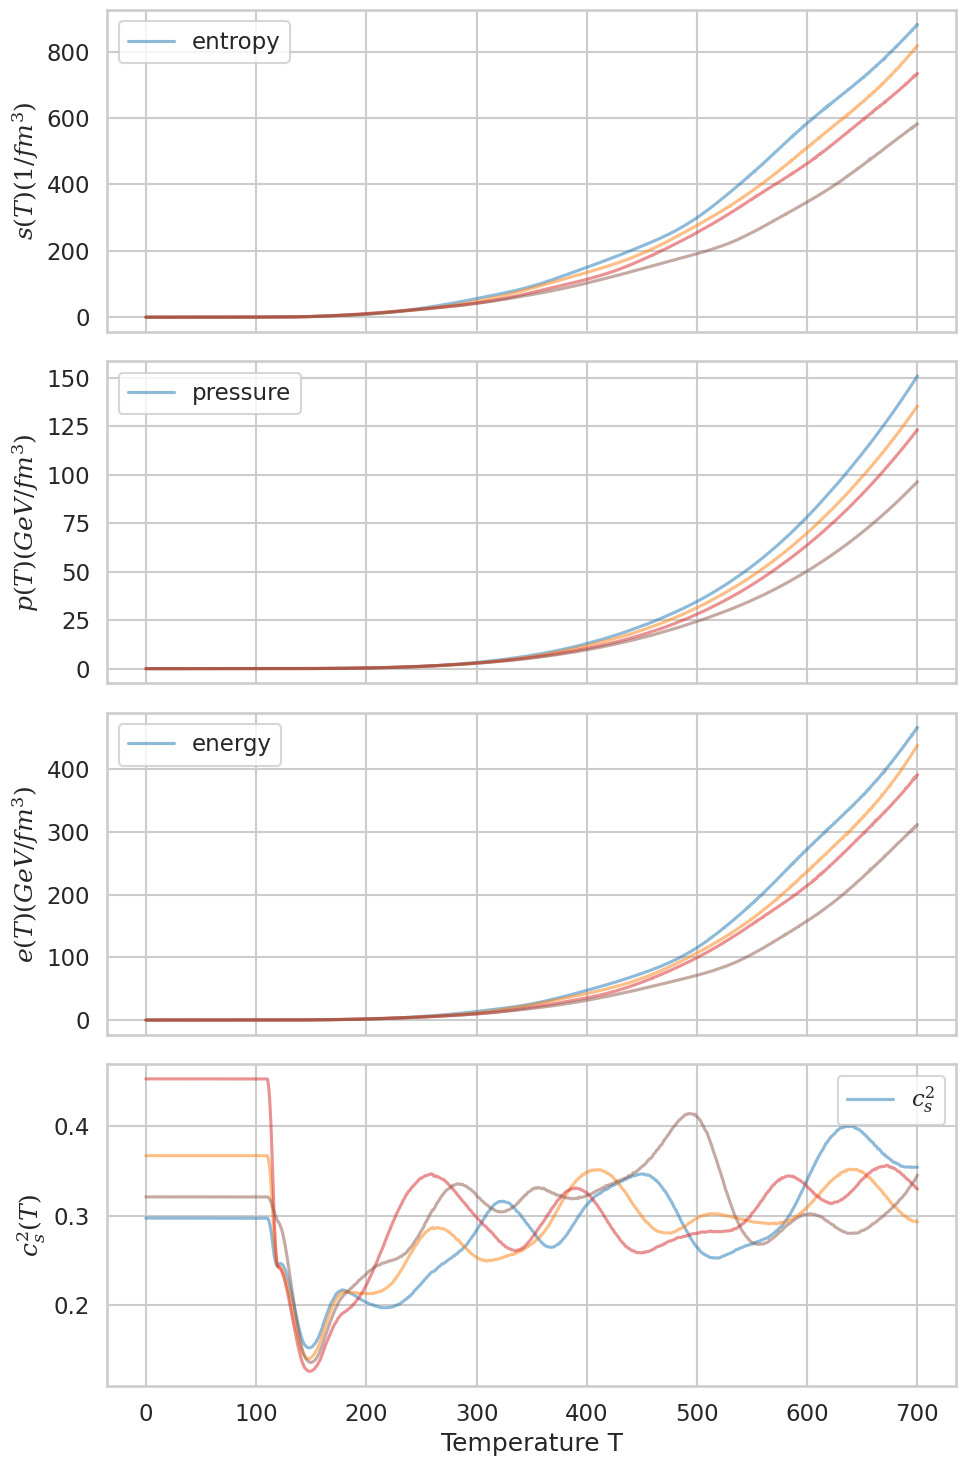

In [188]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    s_plot = []
    p_plot = []
    e_plot = []
    T_divide = np.round(np.arange(50, 700 + 0.001, 0.1), 10)
    T_down_divide = np.round(np.arange(50, 119.9 + 0.001, 0.1), 10)
    
    cs2_sample_plot = generate_sample()
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)
    
    s_plot = np.concatenate([s_extrap_pwr(T_range_down, T_range_up, s_up_vec, P_up_vec), 
                                  s_up_vec])

    P_plot = np.concatenate([P_extrap_pwr(T_range_down, T_range_up, s_up_vec, P_up_vec), 
                               P_up_vec])
    
    e_plot = s_plot*T_total - P_plot

    cs2_vec_plot = np.concatenate([cs2_extrap_pwr(T_range_down[0:1100], T_range_up, s_up_vec, P_up_vec), cs2_interp_plot(T_range_up)])

    cs2_pwr_plot = interp1d(T_interp_cs2, cs2_vec_plot, kind='quadratic')

    color = colors[i] 
    axs[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total, P_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total, cs2_pwr_plot(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[3].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_pwr.png')
plt.show()

/tmp/ipykernel_16473/265740523.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


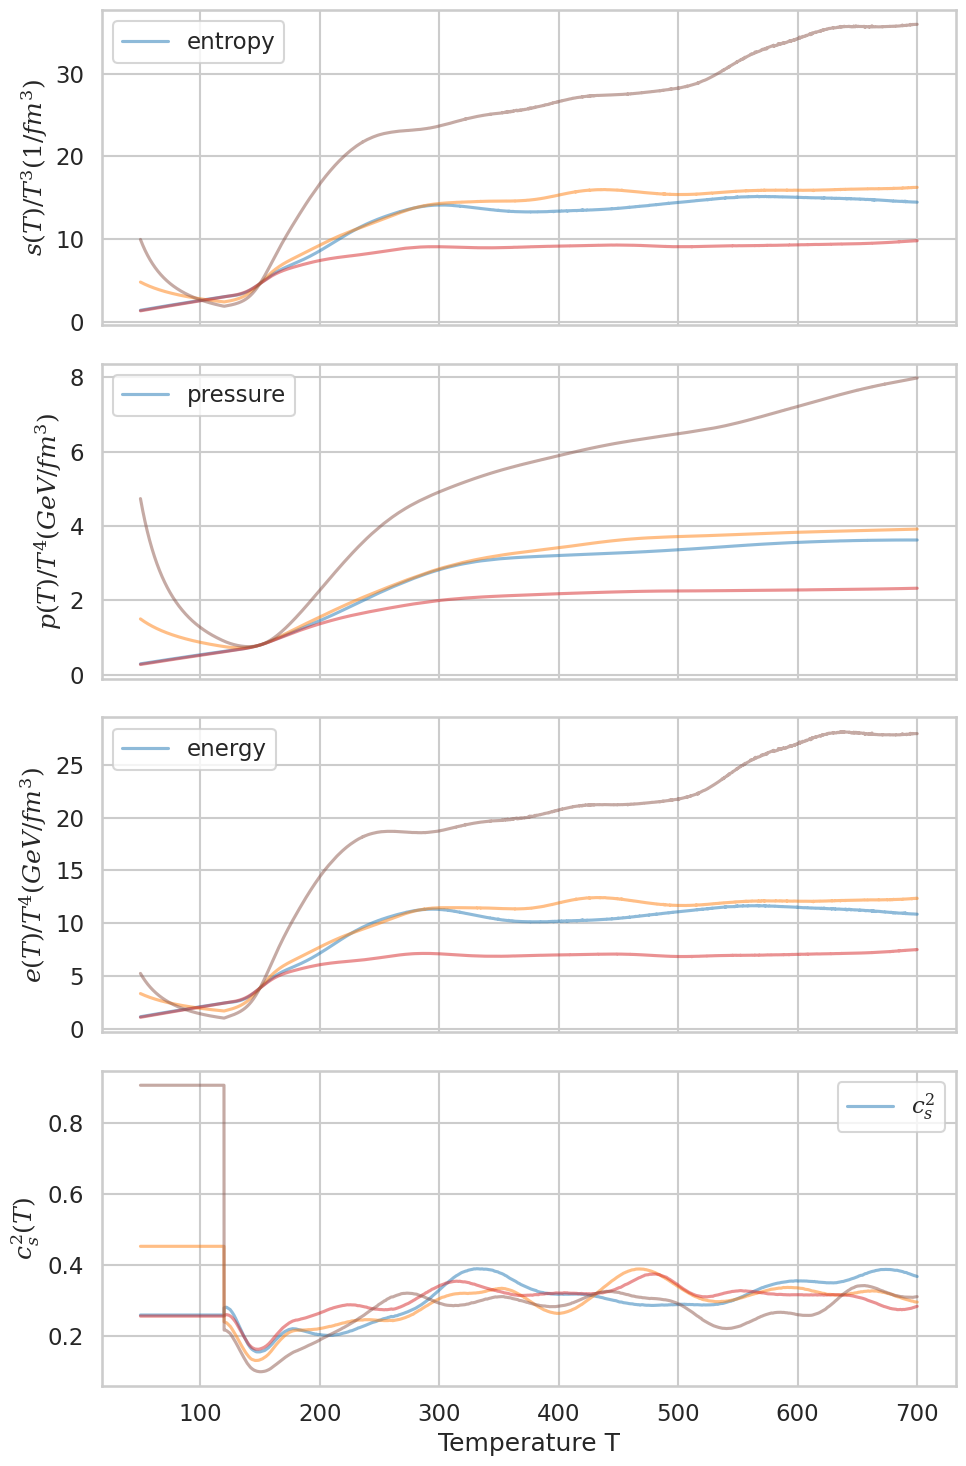

In [32]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    s_plot = []
    p_plot = []
    e_plot = []
    T_divide = np.round(np.arange(50, 700 + 0.001, 0.1), 10)
    T_down_divide = np.round(np.arange(50, 119.9 + 0.001, 0.1), 10)
    
    cs2_sample_plot = generate_sample()
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)
    
    s_plot = np.concatenate([s_extrap_pwr(T_down_divide, T_range_up, s_up_vec, P_up_vec), 
                                  s_up_vec])

    P_plot = np.concatenate([P_extrap_pwr(T_down_divide, T_range_up, s_up_vec, P_up_vec), 
                               P_up_vec])
    
    e_plot = s_plot*T_divide - P_plot

    cs2_vec_plot = np.concatenate([cs2_extrap_pwr(T_down_divide, T_range_up, s_up_vec, P_up_vec), cs2_interp_plot(T_range_up)])

    color = colors[i] 

    color = colors[i] 
    axs[0].plot(T_divide, s_plot/T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_divide, P_plot/T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_divide, e_plot/T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_divide, cs2_vec_plot, color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
axs[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[3].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_pwr_scaled.png')
plt.show()

## Downwards extrap weighted using HRG

In [189]:
T_range_hrg = np.round(np.arange(0, 110, 0.1), 10)

T_test= np.round(np.arange(80, 140 + 0.001, 0.1), 10)

T_range_interp = T_total[1100:1200]

w_range = np.linspace(0, 1, 100)

In [60]:
def P_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    p_down = []
    for temp in T: 
        total = 0.0
        for m, g in zip(m_fermions, g_f):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <=1:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 0), limit=200)
                total += result

        #print(temp, total)
        p_down.append(total)

    return p_down  # MeV^4

def e_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    e_down = []
    for temp in T: 
        total = 0.0     
        for m, g in zip(m_fermions, g_f):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 0), limit=200)
                total += result

        e_down.append(total)

    return e_down  # MeV^4

In [63]:
#HRG vectors low T

P_extrap_hrg_vec = P_extrap_hrg(T_range_hrg, m_fermions, g_f, m_bosons, g_b)
e_extrap_hrg_vec = e_extrap_hrg(T_range_hrg, m_fermions, g_f, m_bosons, g_b)

s_extrap_hrg_vec =[]
for i in range(0, len(e_extrap_hrg_vec)):
    if i == 0:
        s_extrap_hrg_vec.append(0)
    else:
        s_extrap_hrg_vec.append((e_extrap_hrg_vec[i] + P_extrap_hrg_vec[i])/T_range_hrg[i])

In [ ]:
#interpolation w/ weights

def weighted_interp(x, val_down, val_up):
    return (1 - x) * val_down + x * val_up

def weighted_total(w_range, T_range_hrg, vec_down, vec_up):
    weighted_vec = []
    for x in w_range:
        weighted_vec.append(weighted_interp(x, vec_down[len(T_range_hrg)-1], vec_up[0]))
    vec_total = np.concatenate([vec_down, weighted_vec, vec_up])
    return vec_total


def weighted_total_test(w_range, T_range_hrg, vec_down, vec_up):
    weighted_vec = []
    for x in w_range:
        weighted_vec.append(weighted_interp(x, vec_down[len(T_range_hrg)-1], vec_up[0]))
    vec_total = np.concatenate([vec_down[1000:1100], weighted_vec, vec_up])
    return vec_total


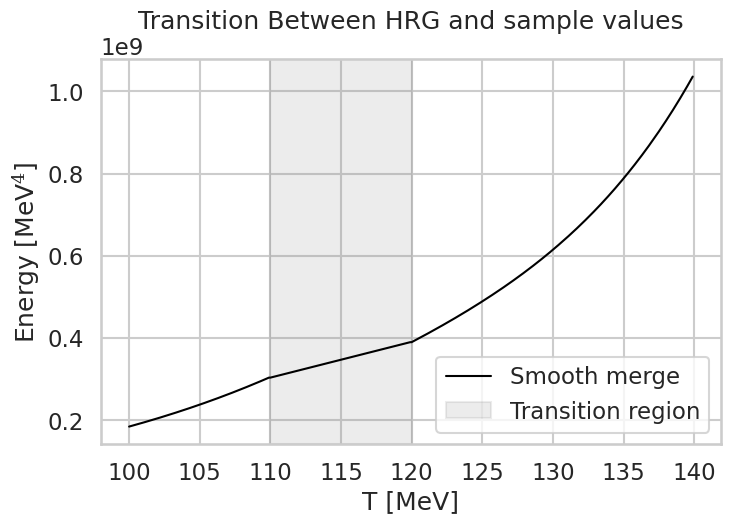

In [202]:
# Plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], weighted_total_test(w_range, T_range_hrg, e_extrap_hrg_vec, e_up[0:200]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_e_transition.png')
plt.show()

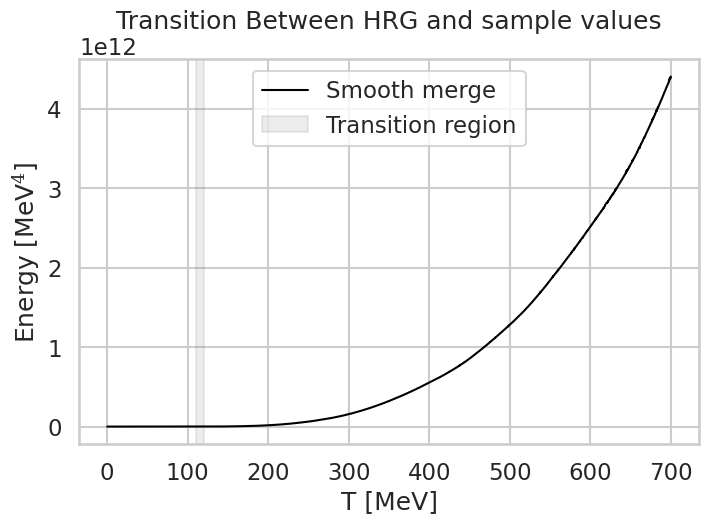

In [331]:

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total, weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
#plt.savefig('./images/hrg_e_transition.png')
plt.show()

In [299]:
P_T = weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up)
e_T = weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up)
s_T = (e_T + P_T)/T_total

/tmp/ipykernel_16473/8980618.py:3: RuntimeWarning: invalid value encountered in divide
  s_T = (e_T + P_T)/T_total


In [181]:
""" # Plot
plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1250], P_w_total[1000:1250] , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_P_transition.png')
plt.show() """

" # Plot\nplt.figure(figsize=(8, 5))\n#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')\n#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')\n\nplt.plot(T_total[1000:1250], P_w_total[1000:1250] , '-', linewidth=1.5, color='black', label='Smooth merge')\nplt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')\nplt.xlabel('T [MeV]')\nplt.ylabel('Pressure [MeV$^4$]')\nplt.legend()\nplt.title('Transition Between HRG and sample values')\nplt.grid(True)\nplt.savefig('./images/hrg_P_transition.png')\nplt.show() "

In [180]:
""" # Plot
plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1250], s_w_total[1000:1250] , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_s_transition.png')
plt.show() """

" # Plot\nplt.figure(figsize=(8, 5))\n#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')\n#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')\n\nplt.plot(T_total[1000:1250], s_w_total[1000:1250] , '-', linewidth=1.5, color='black', label='Smooth merge')\nplt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')\nplt.xlabel('T [MeV]')\nplt.ylabel('Entropy [MeV$^3$]')\nplt.legend()\nplt.title('Transition Between HRG and sample values')\nplt.grid(True)\nplt.savefig('./images/hrg_s_transition.png')\nplt.show() "

In [ ]:
#weighted interp

# Transition range
""" T_a, T_b = 100, 130  # for example ±10 MeV around switch

# For derivative continuity, use quintic smoothstep (C²)
def quintic_smoothstep(t):
    return t**3 * (10 - 15*t + 6*t**2)

def weight(T):
    t = (T - T_a) / (T_b - T_a)
    t = np.clip(t, 0, 1)
    return quintic_smoothstep(t)

def logistic_weight(T, T_a=100, T_b=130, k=0.5):
    midpoint = 0.5*(T_a + T_b)
    return 1 / (1 + np.exp(-k * (T - midpoint))) """

In [70]:
""" with open("./check_files/thermo_check_hrg.txt", "w") as f:
    s = s_weighted_total(T_total,  T_range_hrg, T_range_up, e_extrap_hrg_vec , e_up, P_extrap_hrg_vec, P_up)
    p = P_weighted_total(T_total, T_range_hrg, T_range_up, P_extrap_hrg_vec, P_up)
    e = e_weighted_total(T_total, T_range_hrg, T_range_up, e_extrap_hrg_vec, e_up)

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-5:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}") """

' with open("./check_files/thermo_check_hrg.txt", "w") as f:\n    s = s_weighted_total(T_total,  T_range_hrg, T_range_up, e_extrap_hrg_vec , e_up, P_extrap_hrg_vec, P_up)\n    p = P_weighted_total(T_total, T_range_hrg, T_range_up, P_extrap_hrg_vec, P_up)\n    e = e_weighted_total(T_total, T_range_hrg, T_range_up, e_extrap_hrg_vec, e_up)\n\n    for i, T in enumerate(T_total):\n        s_value = s[i]\n        p_value = p[i]\n        e_value = e[i]\n        check = e_value + p_value\n        expected = s_value * T\n        diff = abs(check - expected)\n\n        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")\n\n        if diff > 1e-5:\n            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}") '

In [ ]:
# cs² from analytic derivatives
# 
# 
# def bose_einstein_prime(k, T, mass):
#     return 1.0/((-np.sqrt(k**2 + mass**2)/T**2)*np.exp(np.sqrt(k**2 + mass**2)/T))

# def fermi_dirac_prime(k, T, mass):
#     return 1.0/((-np.sqrt(k**2 + mass**2)/T**2)*np.exp(np.sqrt(k**2 + mass**2)/T))

# def pressure_integrand_prime(k, g, T, mass, eta):
#     if eta == 1:
#         return (g/(6.0*(np.pi)**2))*(k**4)*fermi_dirac(k, T, mass)/(np.sqrt(k**2 + mass**2))
#     elif eta == 0:
#         return (g/(6.0*(np.pi)**2))*(k**4)*bose_einstein(k, T, mass)/(np.sqrt(k**2 + mass**2))
#     else:
#         raise ValueError("eta must be 0 or 1")

# def energy_integrand_prime(k, g, T, mass, eta):
#     if eta == 1:
#         return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*fermi_dirac(k, T, mass)
#     elif eta == 0:
#         return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*bose_einstein(k, T, mass)

# def pressure_hrg_prime(T, m_fermions, g_f, m_bosons, g_b):
#     total = 0.0
#     for m, g in zip(m_fermions, g_f):
#         result, _ = quad(pressure_integrand_prime, 0, 10000, args=(g, T, m, 1), limit=200)
#         total += result

#     for m, g in zip(m_bosons, g_b):
#         result, _ = quad(pressure_integrand_prime, 0, 10000, args=(g, T, m, 0), limit=200)
#         total += result

#     return total  # MeV^4

# def energy_hrg_prime(T, m_fermions, g_f, m_bosons, g_b):
#     total = 0.0
#     for m, g in zip(m_fermions, g_f):
#         result, _ = quad(energy_integrand_prime, 0, 10000, args=(g, T, m, 1), limit=200)
#         total += result

#     for m, g in zip(m_bosons, g_b):
#         result, _ = quad(energy_integrand_prime, 0, 10000, args=(g, T, m, 0), limit=200)
#         total += result

#     return total


# def entropy_prime(T, m_fermions, g_f, m_bosons, g_b):
#     first_dev = 1/T*(energy_hrg_prime(T, m_fermions, g_f, m_bosons, g_b) + pressure_hrg_prime(T, m_fermions, g_f, m_bosons, g_b))
#     scnd_dev = -1/T**2*(energy_hrg(T, m_fermions, g_f, m_bosons, g_b) + pressure_hrg(T, m_fermions, g_f, m_bosons, g_b))
#     return first_dev + scnd_dev
    
# for T in T_range_hrg:
#     if T <= 3:
#         ds_dT.append(entropy_prime(T+0.08, m_fermions, g_f, m_bosons, g_b))
#     else:
#         ds_dT.append(entropy_prime(T, m_fermions, g_f, m_bosons, g_b))  

# cs2_down_vec = []
# for i in range(0, len(T_range_hrg)):
#     if i <= 30:
#         cs2_down_vec.append(entropy_down_vec[i]/((T_range_hrg[i]+0.5)*(ds_dT[i]+0.5)))
#     else:
#         cs2_down_vec.append(entropy_down_vec[i]/(T_range_hrg[i]*ds_dT[i]))

In [144]:
#cs² from numeric gradients

dP_dT = np.gradient(P_w_total[0:1200], T_total[0:1200])
de_dT = np.gradient(e_w_total[0:1200], T_total[0:1200])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_low = dP_dT / de_dT

# Fill NaNs with first valid value
cs2_hrg_low[np.isnan(cs2_hrg_low)] = cs2_hrg_low[~np.isnan(cs2_hrg_low)][0]

cs2_numeric_low = np.concatenate([cs2_hrg_low, cs2_interp(T_range_up)])


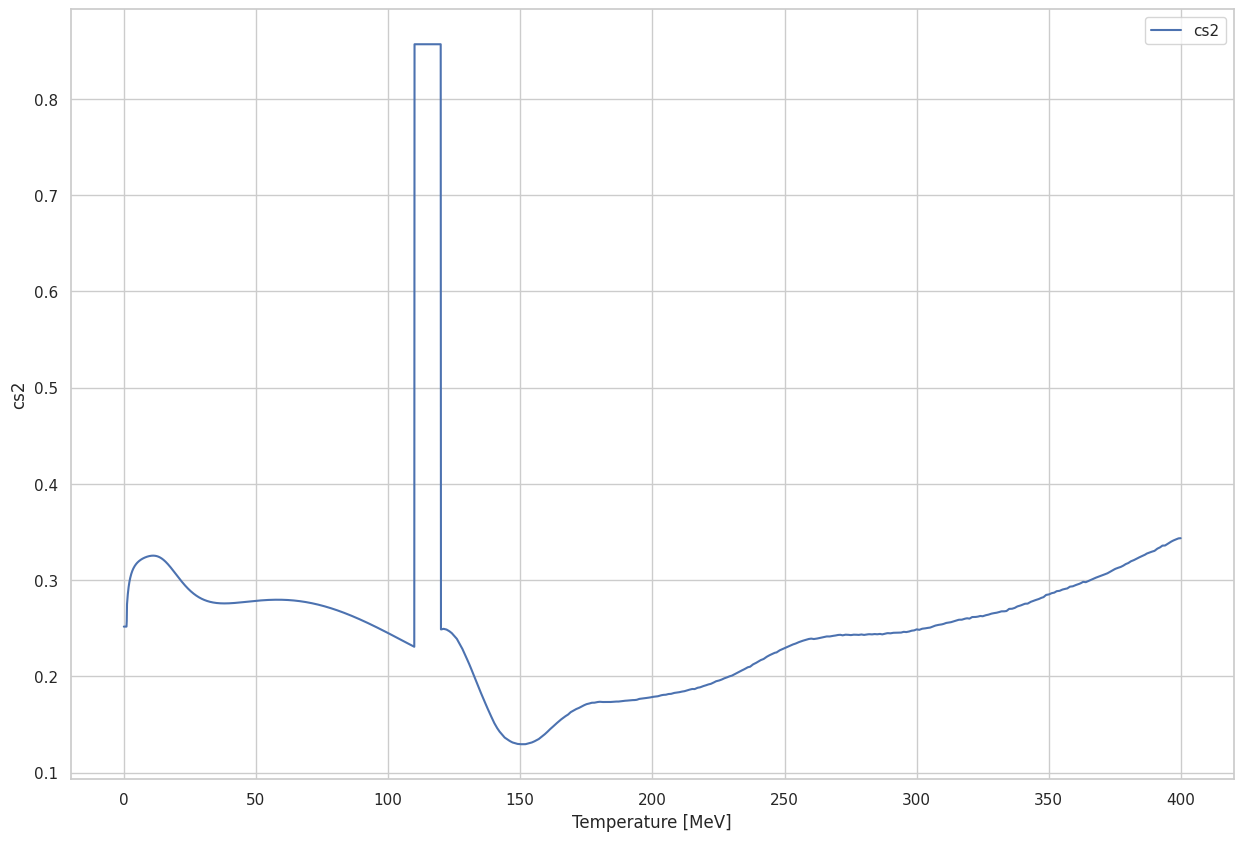

In [145]:
#cs2 numeric dev plot

df = pd.DataFrame({'T': T_total[0:4000], 'cs2':cs2_numeric_low[0:4000]})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.legend()
plt.savefig('./images/cs2_dev_transition.png')
plt.show()

In [ ]:
dP_dT = np.gradient(P_extrap_hrg_vec, T_range_hrg)
de_dT = np.gradient(e_extrap_hrg_vec, T_range_hrg)

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_interp = dP_dT / de_dT

# Fill NaNs with first valid value
cs2_hrg_to_interp[np.isnan(cs2_hrg_to_interp)] = cs2_hrg_to_interp[~np.isnan(cs2_hrg_to_interp)][0]

In [192]:
T_range_interp = np.concatenate([T_range_hrg, T_range_up])

cs2_total_w = np.concatenate([cs2_hrg_to_interp, cs2_interp(T_range_up)])

cs2_interp_w = interp1d(T_range_interp, cs2_total_w, kind='quadratic')

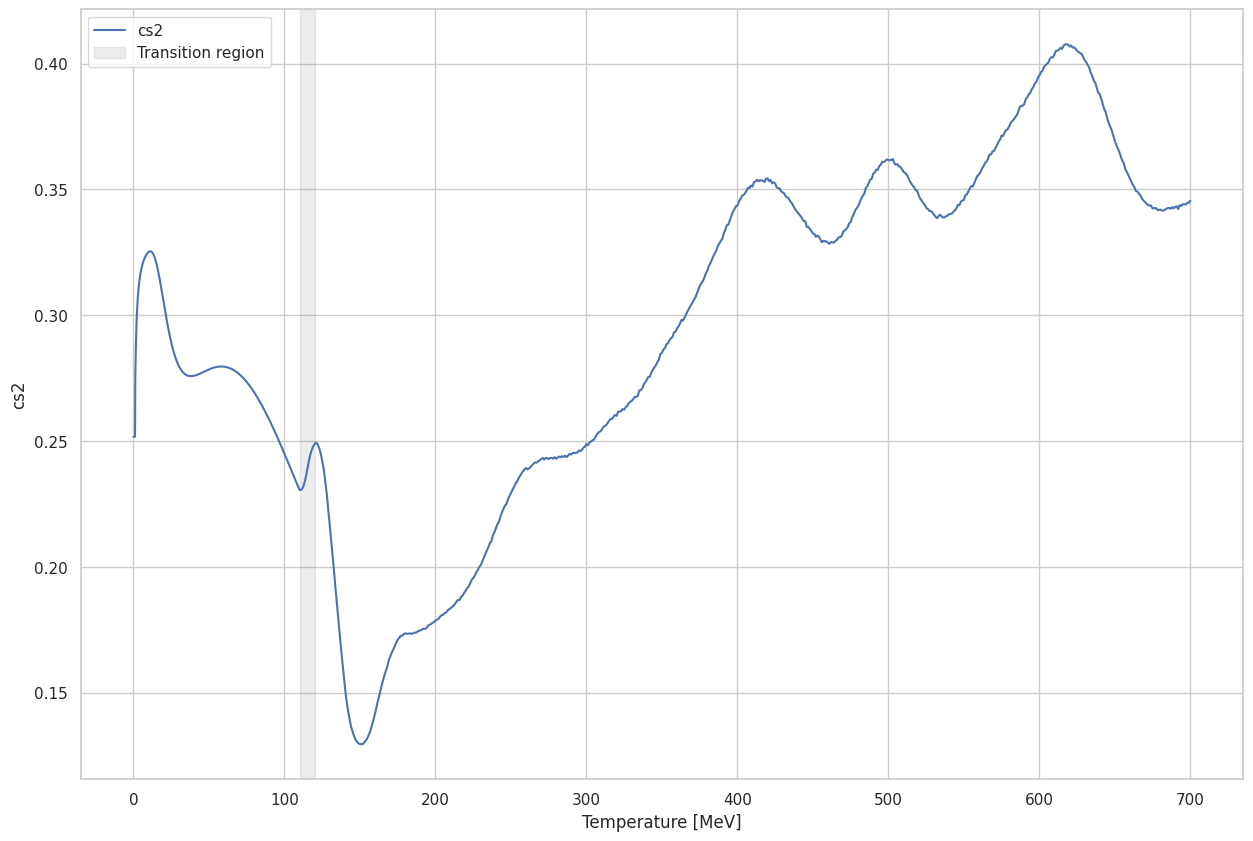

In [187]:
#cs2 interp plot

df = pd.DataFrame({'T': T_total, 'cs2':cs2_interp_w(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.legend()
plt.savefig('./images/cs2_transition_interp.png')
plt.show()

/tmp/ipykernel_16473/1246766538.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)
/tmp/ipykernel_16473/1246766538.py:31: RuntimeWarning: invalid value encountered in divide
  s_plot = (p_plot + e_plot)/T_total


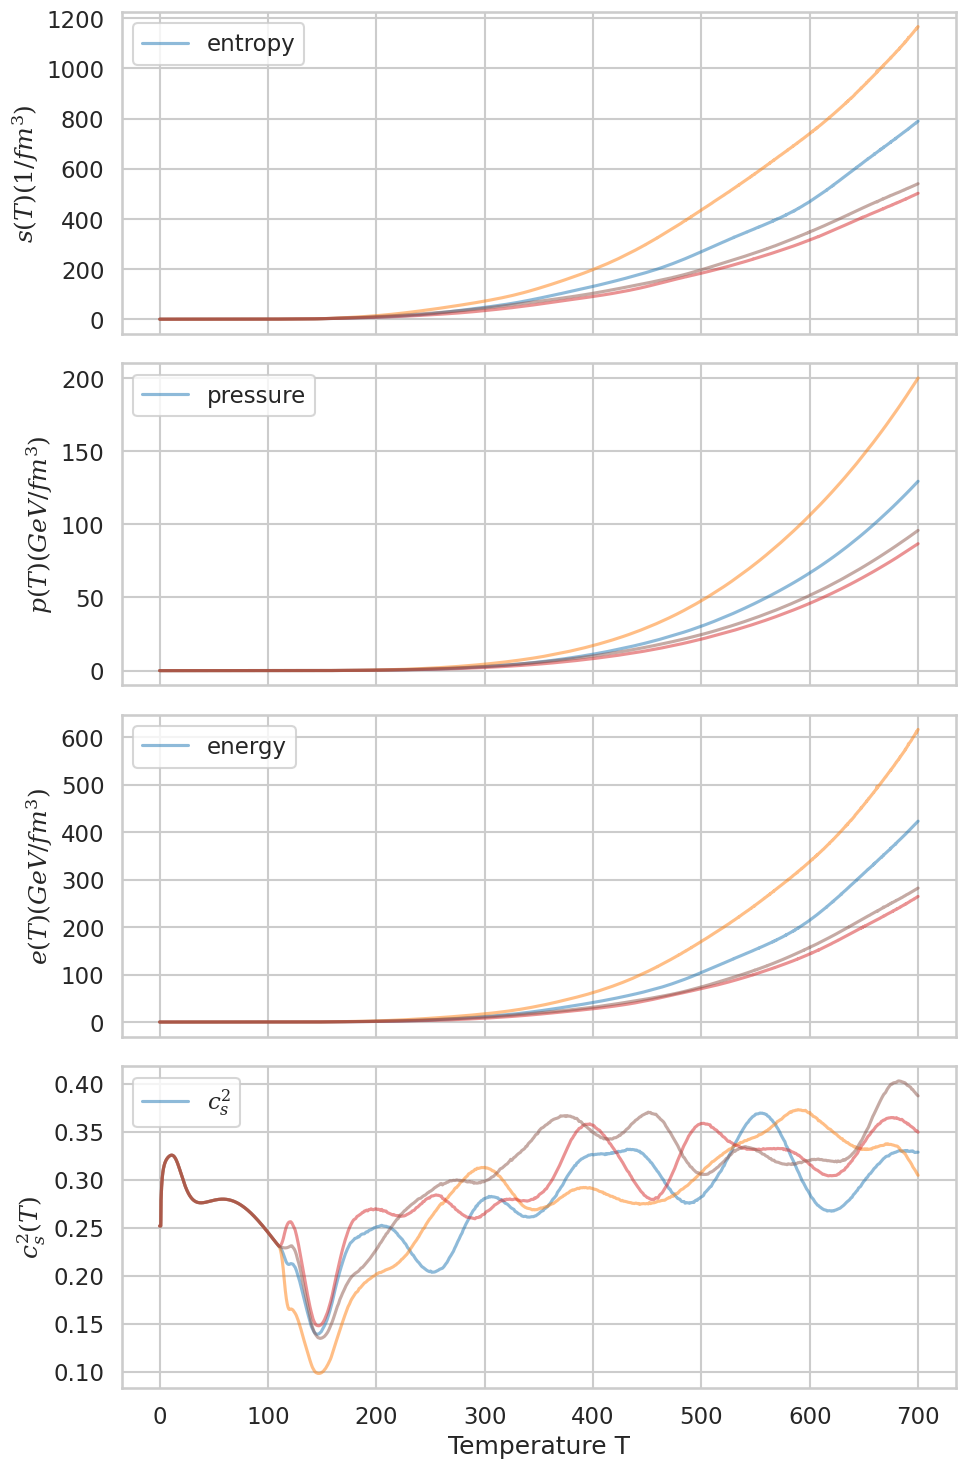

In [194]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    s_plot = []
    p_plot = []
    e_plot = []
    cs2_hrg_plot = []
    
    cs2_sample_plot = generate_sample()
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)

    e_up_vec = s_up_vec*T_range_up - P_up_vec

    p_plot = weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up_vec)

    e_plot = weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up_vec)

    s_plot = (p_plot + e_plot)/T_total

    cs2_w_plot = np.concatenate([cs2_hrg_to_interp, cs2_interp_plot(T_range_up)])

    cs2_interp_w_plot = interp1d(T_range_interp, cs2_w_plot, kind='quadratic')
    #print("Run", [i], cs2_interp_plot(T_total[1500:1700]))

    color = colors[i] 
    axs[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total, p_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total, cs2_interp_w_plot(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[3].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_weighted.png')
plt.show()

/tmp/ipykernel_16473/1622989495.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


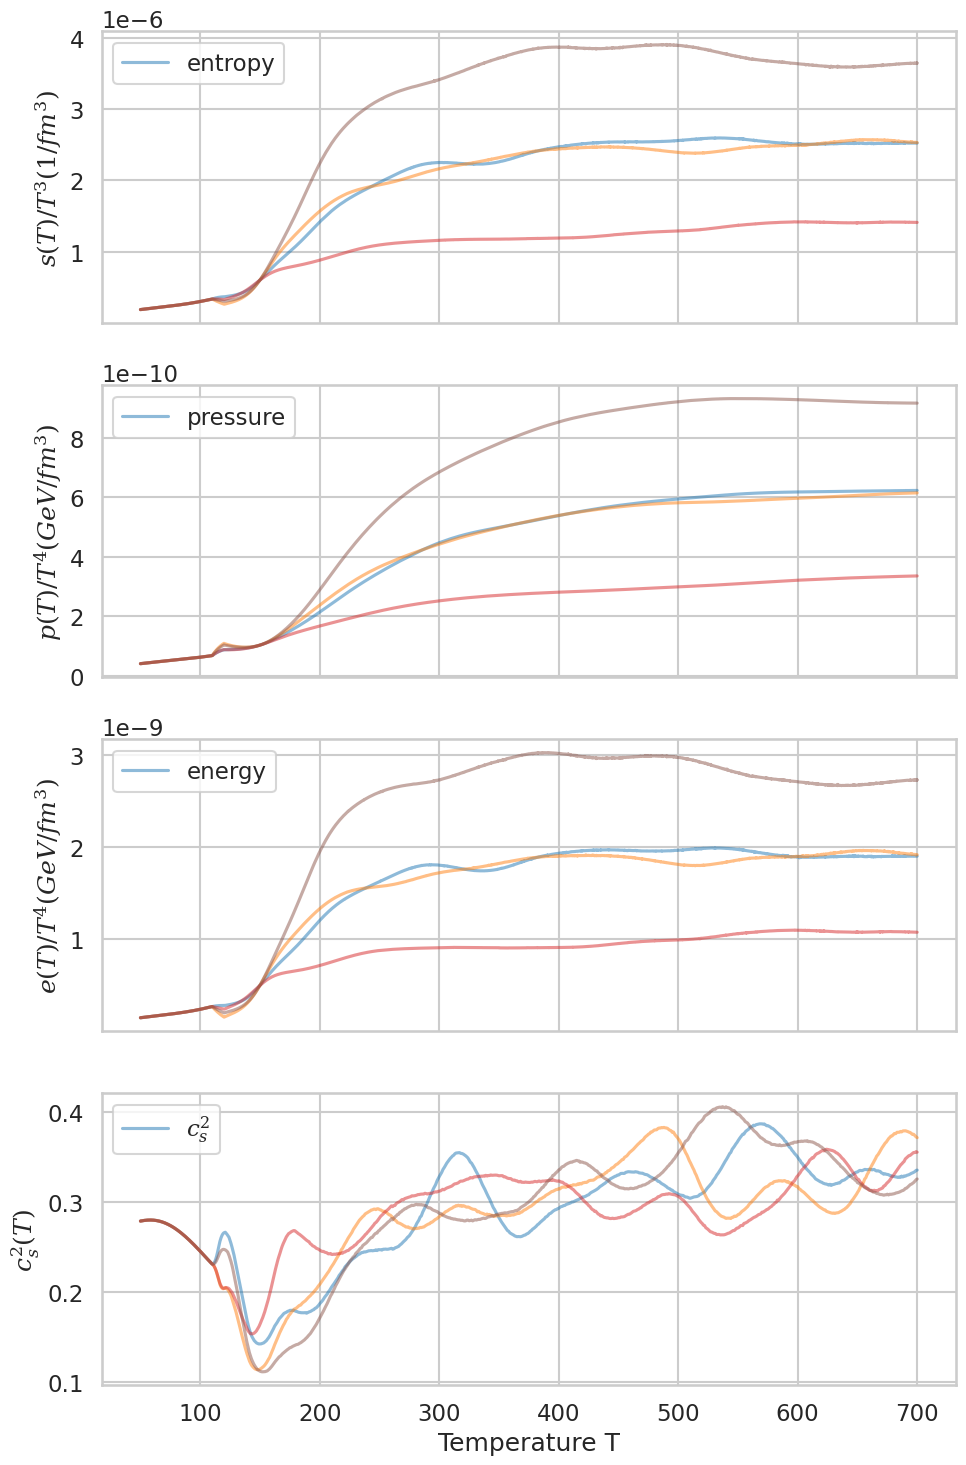

In [200]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    s_plot = []
    p_plot = []
    e_plot = []
    cs2_vec_plot = []
    
    cs2_sample_plot = generate_sample()
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)

    e_up_vec = s_up_vec*T_range_up - P_up_vec
    
    p_plot_w = weighted_total(w_range, T_range_hrg[500:], P_extrap_hrg_vec[500:], P_up_vec)

    e_plot_w = weighted_total(w_range, T_range_hrg[500:], e_extrap_hrg_vec[500:], e_up_vec)

    s_plot_w = (p_plot_w + e_plot_w)/T_total[500:]

    cs2_w_plot = np.concatenate([cs2_hrg_to_interp, cs2_interp_plot(T_range_up)])

    cs2_interp_w_plot = interp1d(T_range_interp, cs2_w_plot, kind='quadratic')

    color = colors[i] 
    axs[0].plot(T_total[500:], s_plot_w*(1/hbarc**3)/(T_total[500:])**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total[500:], p_plot_w*MeV4_to_GeV_fm3/(T_total[500:])**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total[500:], e_plot_w*MeV4_to_GeV_fm3/(T_total[500:])**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total[500:], cs2_interp_w_plot(T_total[500:]), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
axs[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[3].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_weighted_scaled.png')
plt.show()


## Jackknife samples

In [36]:
T_js = np.linspace(120,260,260-120+1)

j_samples = data.iloc[:, 3:] # selects all lines and all columns after the 3rd
jk_mean = j_samples.mean(axis=1) #mean over each row (axis=1), over the 48 samples for each T
N = j_samples.shape[1]
#print(j_samples.T)

#transpose of j_sample (N_T, N_samples) to (N_samples, N_T), subtracts the mean from each column
X = j_samples.T.sub(jk_mean, axis=1)  

#calculate covariance matrix
var_jk = ((N-1)/N) * ((j_samples.sub(jk_mean, axis=0)) ** 2).sum(axis=1)
cov_matrix = (X.T @ X)*((N-1)/N)

#print(X.T)
#print(cov_matrix)
print(var_jk)

0      0.001320
1      0.001419
2      0.001486
3      0.001516
4      0.001505
         ...   
136    0.000158
137    0.000164
138    0.000171
139    0.000177
140    0.000182
Length: 141, dtype: float64


In [ ]:
#correlation matrix

cov_np = cov_matrix.to_numpy()
corr_matrix = np.zeros_like(cov_np)

#print(cov_np[0, 141])

for i in range(0, 140):
    for j in range(0, 140):
        denom = np.sqrt(cov_np[i, i] * cov_np[j, j])
        if denom > 0:
            corr_matrix[i, j] = cov_np[i, j] / denom
        else:
            corr_matrix[i, j] = 0


In [37]:
def is_positive_definite_eig(matrix):
    return np.all(np.linalg.eigvalsh(matrix) >= 1e-10)

print(np.linalg.eigvalsh(cov_matrix))

print(is_positive_definite_eig(cov_matrix)) 


[-1.37953410e-18 -1.00791853e-18 -8.12938652e-19 -4.26212799e-19
 -3.23060037e-19 -3.10271275e-19 -2.43912438e-19 -2.33330365e-19
 -2.13351936e-19 -1.78103056e-19 -1.56530479e-19 -1.41967759e-19
 -1.28934727e-19 -1.22349042e-19 -1.16184186e-19 -1.12074382e-19
 -1.03605560e-19 -1.00509891e-19 -9.86220640e-20 -9.08773574e-20
 -8.69645017e-20 -7.74414775e-20 -7.58653676e-20 -6.83250596e-20
 -6.57249628e-20 -6.47708425e-20 -6.01014723e-20 -5.68009690e-20
 -5.44865352e-20 -5.20517713e-20 -5.03829882e-20 -4.33444677e-20
 -4.20283382e-20 -3.91919948e-20 -3.88044430e-20 -3.50977871e-20
 -3.20519034e-20 -3.16233060e-20 -2.79668829e-20 -2.53664604e-20
 -2.37127779e-20 -2.17925140e-20 -1.77815719e-20 -1.61916935e-20
 -1.48289214e-20 -1.44837973e-20 -1.29571452e-20 -1.02023031e-20
 -8.88129638e-21 -7.38605416e-21 -6.27563017e-21 -5.22978914e-21
 -3.87635315e-21 -2.80733875e-21  8.49453097e-23  1.01091349e-21
  1.09973006e-21  3.13980449e-21  5.63801228e-21  8.26621463e-21
  9.02624088e-21  1.20200

In [38]:
with open("jk_check.txt", "w") as f:
    for i, T in enumerate(T_js):
        diff = (jk_mean - GP_mean_file).iloc[i]
        diff_2 = (lat_cs2.error - np.sqrt(var_jk)).iloc[i]

        f.write(f"T = {T:.2f} MeV, mean diff = {diff:.2e}, var diff = {diff_2:.2e}\n")


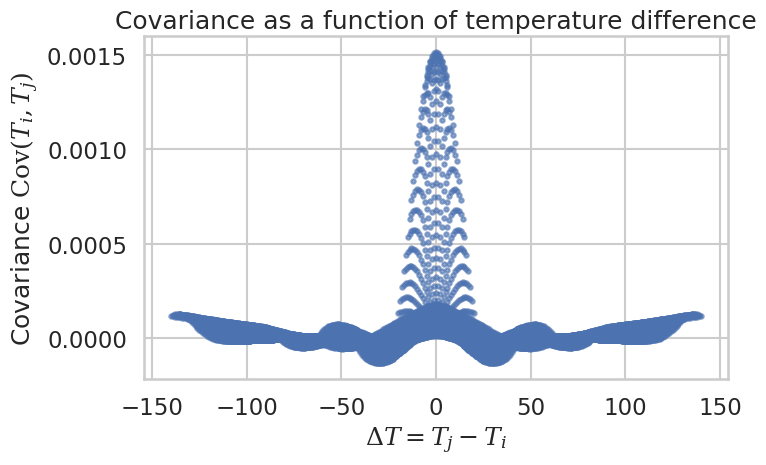

In [39]:
T = data.iloc[:, 0].values
delta_T = T[np.newaxis, :] - T[:, np.newaxis]  # shape: (n_T, n_T)

# Flatten both matrices
delta_T_flat = delta_T.flatten()
cov_flat = cov_matrix.to_numpy().flatten()

# Plot covariance vs. ΔT
plt.figure(figsize=(8, 5))
plt.scatter(delta_T_flat, cov_flat, s=10, alpha=0.6)
plt.xlabel(r'$\Delta T = T_j - T_i$')
plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
plt.title("Covariance as a function of temperature difference")
plt.grid(True)
plt.tight_layout()

#plt.savefig('cov_matrix.png')
plt.show()

/tmp/ipykernel_16473/2535571170.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 141)


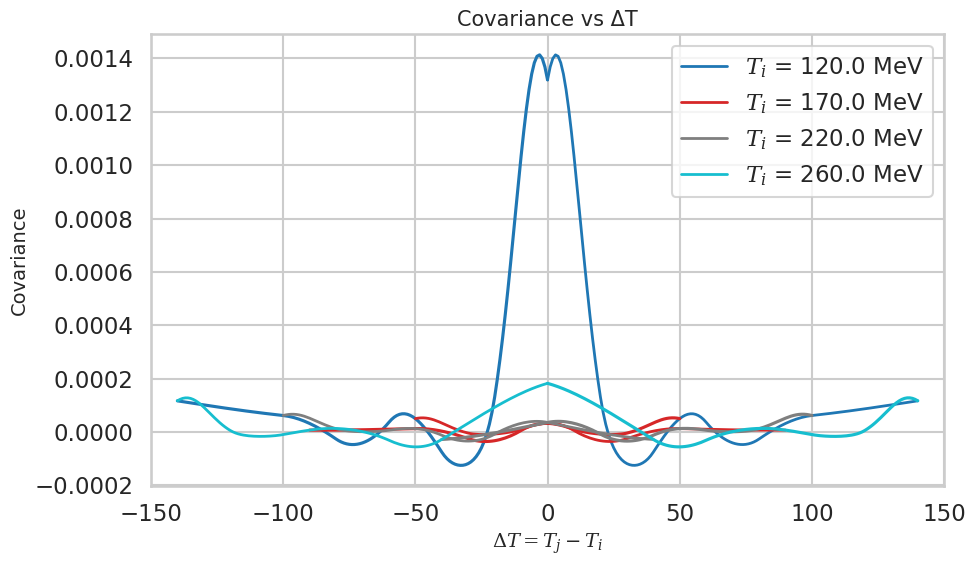

In [40]:
#plot slices

T = data.iloc[:, 0].values
cov = cov_matrix.to_numpy()

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 50, 100, 140]
cmap = cm.get_cmap('tab10', 141)  
colors = [cmap(i) for i in range(141)]
#print(len(colors))

for i in rows_to_plot:
    color = colors[i] 
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    #delta_T_plot = np.concatenate([delta_T_minus, delta_T_plus])
    #cov_plot = np.concatenate([cov[i, :], cov[i, :]])
    cov_row = cov[i, :]

    plt.plot(delta_T_plus, cov[:, i], color=color, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)
    plt.plot(delta_T_minus, cov[:, i], color=color)
    #plt.plot(delta_T_plot, cov_plot, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT', fontsize=15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.xlim(-150, 150)
plt.savefig("./images/covariance_slices.png")
plt.show()

In [41]:
#curve fitting save to file

def gaussian(x, sigma, l):
    return sigma * np.exp(-(x**2) / (2 * l**2))

T = data.iloc[:, 0].values
cov = cov_matrix.to_numpy()

sigma_fit_vec = []
l_fit_vec = []

with open("gaussian_fit_results.dat", "w") as f:
    f.write("# T    sigma    l\n")
    
    for i in range(len(T)):
        delta_T_plus = T - T[i]
        delta_T_minus = T[i] - T
        delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])
        cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])

        try:
            #p0: initial guess for the parameters
            # Here, we use the diagonal element as the initial guess for sigma and a fixed value for l
            popt, _ = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
            # unpacks the two fitted parameters from popt:
            sigma_fit, l_fit = popt
        except RuntimeError:
            sigma_fit, l_fit = np.nan, np.nan

        sigma_fit_vec.append(sigma_fit)
        l_fit_vec.append(l_fit)

        f.write(f"{T[i]}  {sigma_fit}  {l_fit}\n")


/tmp/ipykernel_16473/2873404945.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', len(rows_to_plot))


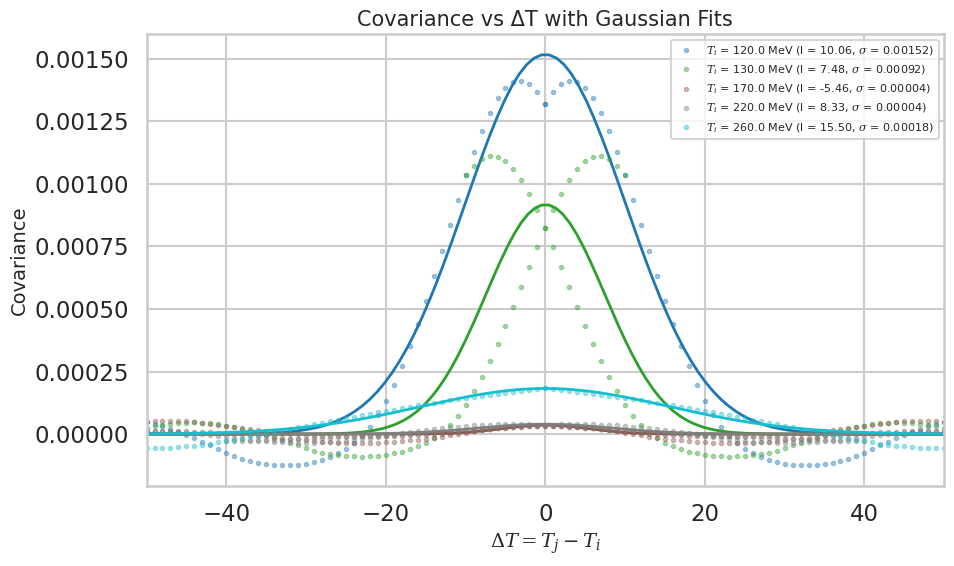

In [282]:
rows_to_plot = [0, 10, 50, 100, 140]
cmap = cm.get_cmap('tab10', len(rows_to_plot))
colors = [cmap(i) for i in range(len(rows_to_plot))]

plt.figure(figsize=(10, 6))

for idx, i in enumerate(rows_to_plot):
    # ΔT for both sides
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])  # match order

    # Fit Gaussian
    popt, pcov = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
    sigma_fit, l_fit = popt

    # Plot data
    plt.plot(delta_T, cov_row, 'o', markersize=3, color=colors[idx], alpha=0.4,
             label=rf"$T_i$ = {T[i]:.1f} MeV (l = {l_fit:.2f}, $\sigma$ = {sigma_fit:.5f})")
    
    # Plot fitted Gaussian
    x_fit = np.linspace(delta_T.min(), delta_T.max(), 300)
    plt.plot(x_fit, gaussian(x_fit, *popt), '-', color=colors[idx], linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT with Gaussian Fits', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/covariance_gaussian_fits.png")
plt.show()

/tmp/ipykernel_16473/589209504.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')  # continuous colormap


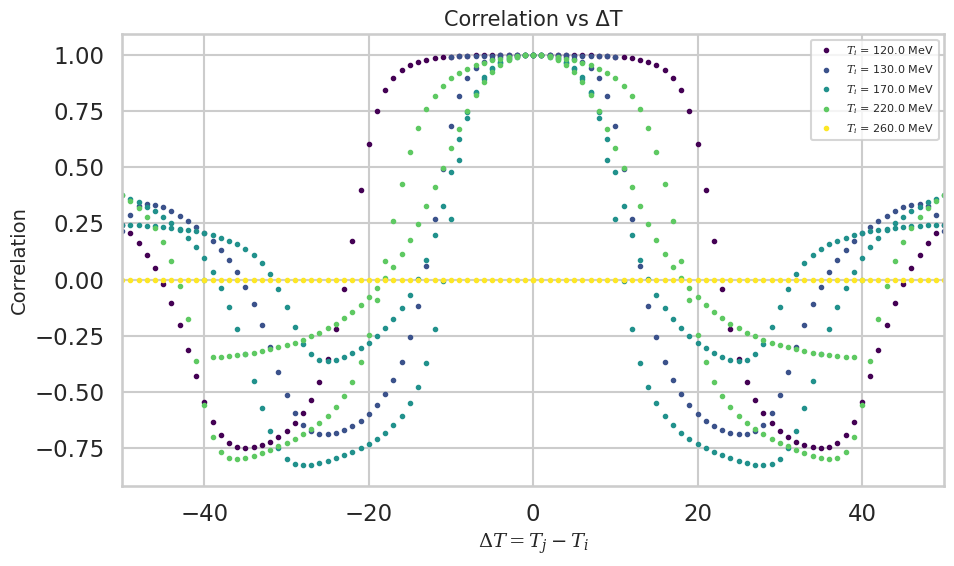

In [283]:
#plot corr matrix

T = data.iloc[:, 0].values

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 10, 50, 100, 140]
""" cmap = cm.get_cmap('viridis', 141)  # or 'coolwarm'
colors = [cmap(i) for i in range(141)] """
#print(len(colors))

cmap = cm.get_cmap('viridis')  # continuous colormap
num_rows = len(rows_to_plot)

for idx, i in enumerate(rows_to_plot):
    color = cmap(idx / (num_rows - 1))

    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    corr_row = np.concatenate([corr_matrix[i, ::-1], corr_matrix[i, :]])

    plt.plot(delta_T_plus, corr_matrix[i, :], 'o', markersize=3, color=color, label=rf"$T_i$ = {T[i]:.1f} MeV")
    plt.plot(delta_T_minus, corr_matrix[i, :], 'o', markersize=3, color=color)
    #plt.plot(delta_T, corr_row, linewidth=2)


plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Correlation', fontsize=14)
plt.title('Correlation vs ΔT', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/corr_slices.png")
plt.show()

In [ ]:
# k = []
# for x1 in T_js:
#     k_row = []
#     for x2 in T_js:
#         k_row.append(kernel_func(x1, x2, sigma, l)) 
#     k.append(k_row)   
# k = np.array(k)
# k[np.diag_indices_from(k)] += 0.001
# Sigma = cholesky(k)

In [187]:
# T_k = np.array(T_js)
# delta_T_k = T_k[np.newaxis, :] - T_k[:, np.newaxis]

# #transf into 1D array
# delta_T_flat_k = delta_T_k.flatten()
# k_flat = k.flatten()
# sigma_flat = Sigma.flatten()

# # Plot covariance vs. ΔT
# plt.figure(figsize=(8, 5))
# plt.scatter(delta_T_flat_k, k_flat, s=10, alpha=0.6)
# plt.xlabel(r'$\Delta T = T_j - T_i$')
# plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
# plt.title("Covariance as a function of temperature difference")
# plt.grid(True)
# plt.tight_layout()
# plt.show()

## Kernel with fitted l and sigma

In [188]:
def generate_sample_fitted():   
    k = []
    mean = [phifromsc2(el) for el in GP_mean_file]
    for x1, l, sigma in zip(T_sampling[0:141], l_fit_vec, sigma_fit_vec):
        k_row = []
        for x2 in T_sampling[0:141]:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling[0:141]))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

In [290]:
""" # Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind='cubic', fill_value="extrapolate")
    
    ax.plot(
        T_sampling[0:141],
        interp_plot(T_sampling[0:141]),
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_fitted.png')
plt.show() """

' # Seaborn style for better visuals\nsns.set(style="whitegrid", context="talk")\n\n# Assume lat_cs2 is a pandas DataFrame with columns \'T\', \'cs2\', and \'error\'\n\nfig, ax = plt.subplots(figsize=(15, 10))\n\nfor i in range(11):\n    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind=\'cubic\', fill_value="extrapolate")\n\n    ax.plot(\n        T_sampling[0:141],\n        interp_plot(T_sampling[0:141]),\n        color=\'blue\',\n        alpha=0.5,\n        label=\'GP samples\' if i == 0 else None\n    )\n\n    # ax.plot(\n    #     T_down,\n    #     y_down,\n    #     color=\'blue\',\n    #     alpha=0.5,\n    #     #label=\'GP samples\' if i == 0 else None\n\n    #)\n\n# Axis labels\nax.set_xlabel("T [MeV]")\nax.set_ylabel(r"$c_s^2$")\n\n# Axis limits\n#ax.set_xlim(120, 700)\n\n# Ticks and frame style\nax.patch.set_edgecolor(\'black\')\nax.patch.set_linewidth(5)\nax.xaxis.set_tick_params(width=5, length=10)\nax.yaxis.set_tick_params(width=5, length=10)\nax.y

## Cs² via jackknife samples

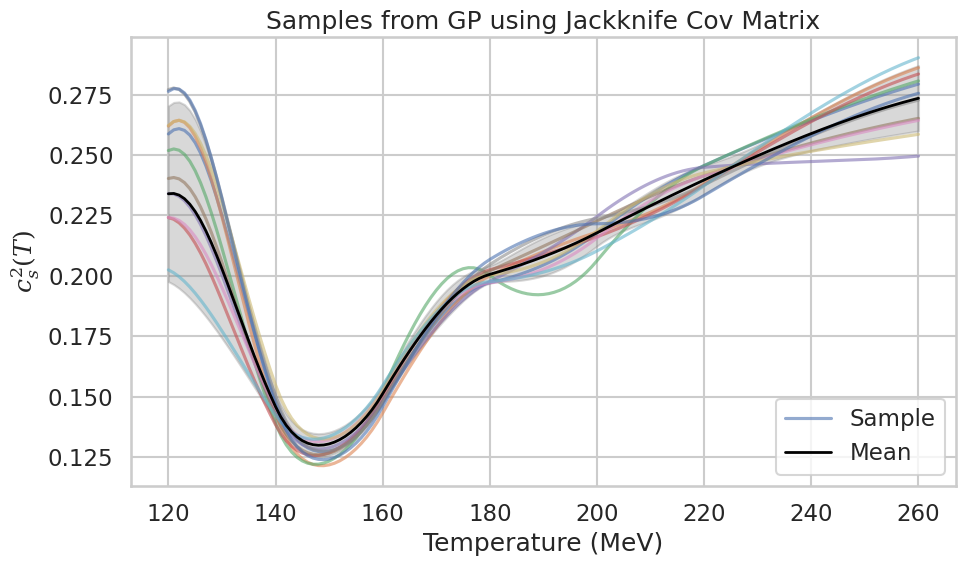

In [44]:
mean_data_jk = GP_mean_file

def generate_sample_from_jk():
    mean = [phifromsc2(el) for el in mean_data_jk]
    
    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_js))
    sample = list(mean + np.dot(cov_matrix, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample


mean_data = j_samples.mean(axis=1)  # shape: (n_T,)

# Step 2: Sample from the GP
n_samples = 11  # number of functions to draw
samples = multivariate_normal(mean=mean_data, cov=cov_matrix, size=n_samples)

# Step 3: Plot the samples
plt.figure(figsize=(10, 6))
for i in range(n_samples):
    plt.plot(T, samples[i], alpha=0.6, label=f'Sample' if i == 0 else None)

# Plot the mean and uncertainty band
std_diag = np.sqrt(np.diag(cov_matrix))
plt.plot(T, mean_data, color='black', lw=2, label='Mean')
plt.fill_between(T, mean_data - std_diag, mean_data + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('cs2_from_jk.png')
plt.show()

## Unconstrained GP

In [45]:
cs2_unc_val = np.full((581), 0.3)

def unconstrained_sample():   
    k = []
    mean_unc = [phifromsc2(el) for el in cs2_unc_val]
    for x1 in T_sampling:
        k_row = []
        for x2 in T_sampling:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling))
    sample = list(mean_unc + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

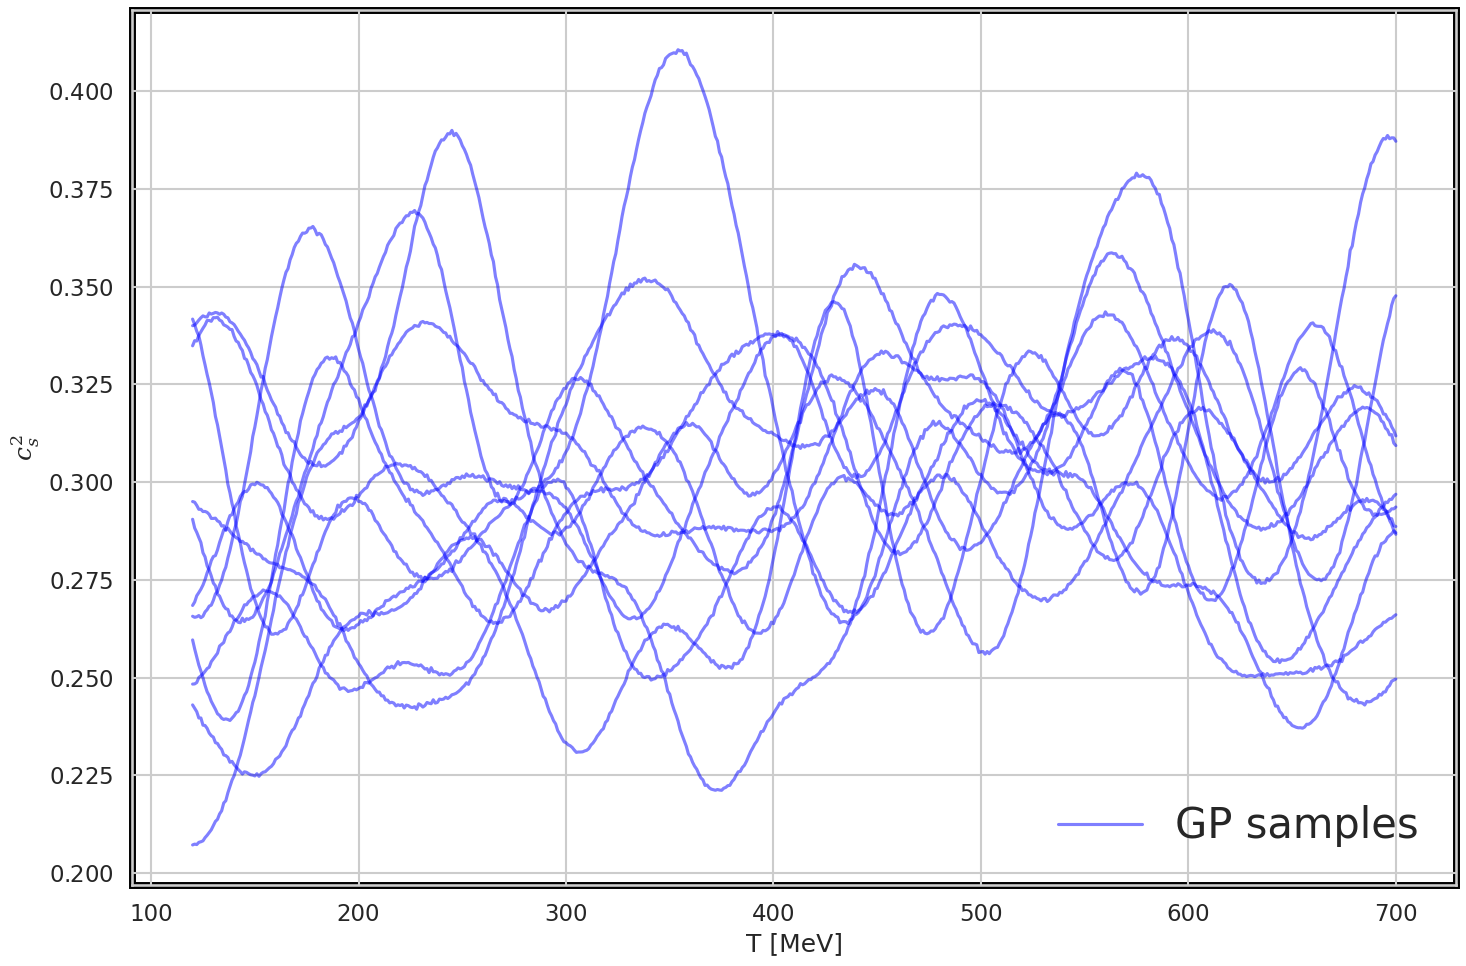

In [46]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    cs2_sample_unc = unconstrained_sample()
    
    ax.plot(
        T_sampling,
        cs2_sample_unc,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_unc.png')
plt.show()

In [47]:
cs2_unc = unconstrained_sample()

cs2_interp_unc = interp1d(T_sampling, cs2_unc)

In [48]:
#entropy, pressure and energy upwards
s_up_unc = entropy_up(s_sw, T_sw, cs2_interp_unc, T_range_up)
s_up_interp_unc = interp1d(T_range_up, s_up_unc, kind='linear', fill_value="extrapolate")

P_up_unc = pressure_up(P_sw, T_sw, T_range_up, s_up_interp_unc)
P_up_interp_unc = interp1d(T_range_up, P_up_unc, kind='linear', fill_value="extrapolate")

e_up_unc = energy_up(s_up_interp_unc, P_up_interp_unc, T_range_up)

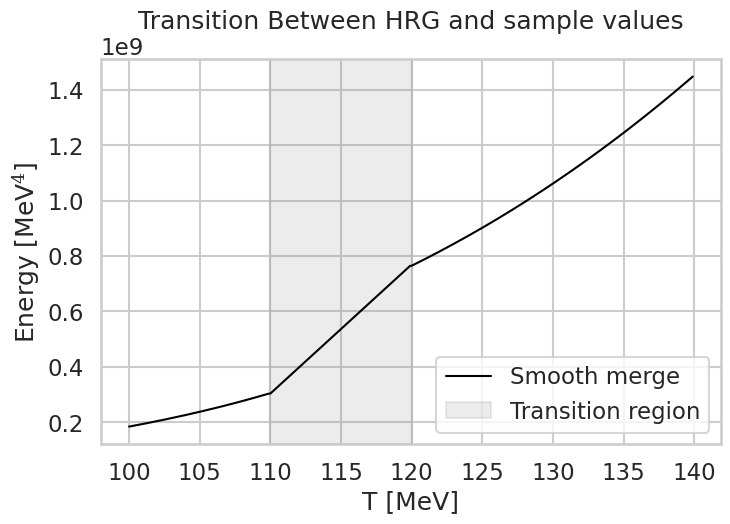

In [284]:
# Plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], weighted_total_test(w_range, T_range_hrg, e_extrap_hrg_vec, e_up_unc[0:200]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_e_transition_unc.png')
plt.show()

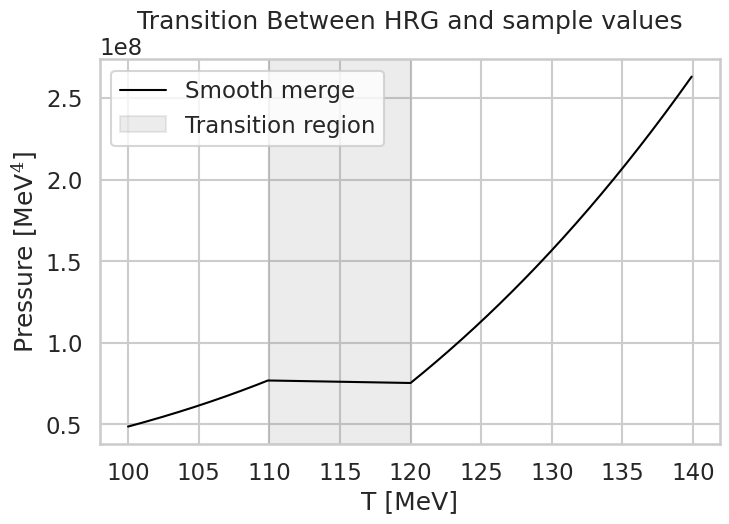

In [203]:
plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], weighted_total_test(w_range, T_range_hrg, P_extrap_hrg_vec, P_up_unc[0:200]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_p_transition_unc.png')
plt.show()

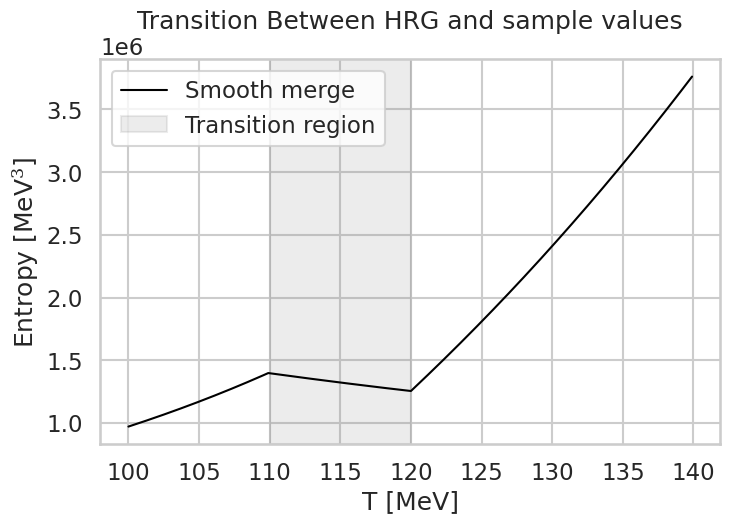

In [204]:
s_plot = (weighted_total_test(w_range, T_range_hrg, P_extrap_hrg_vec, P_up_unc[0:200]) + weighted_total_test(w_range, T_range_hrg, P_extrap_hrg_vec, P_up_unc[0:200]))/T_total[1000:1400]

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[1000:1400], s_plot , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_s_transition_unc.png')
plt.show()

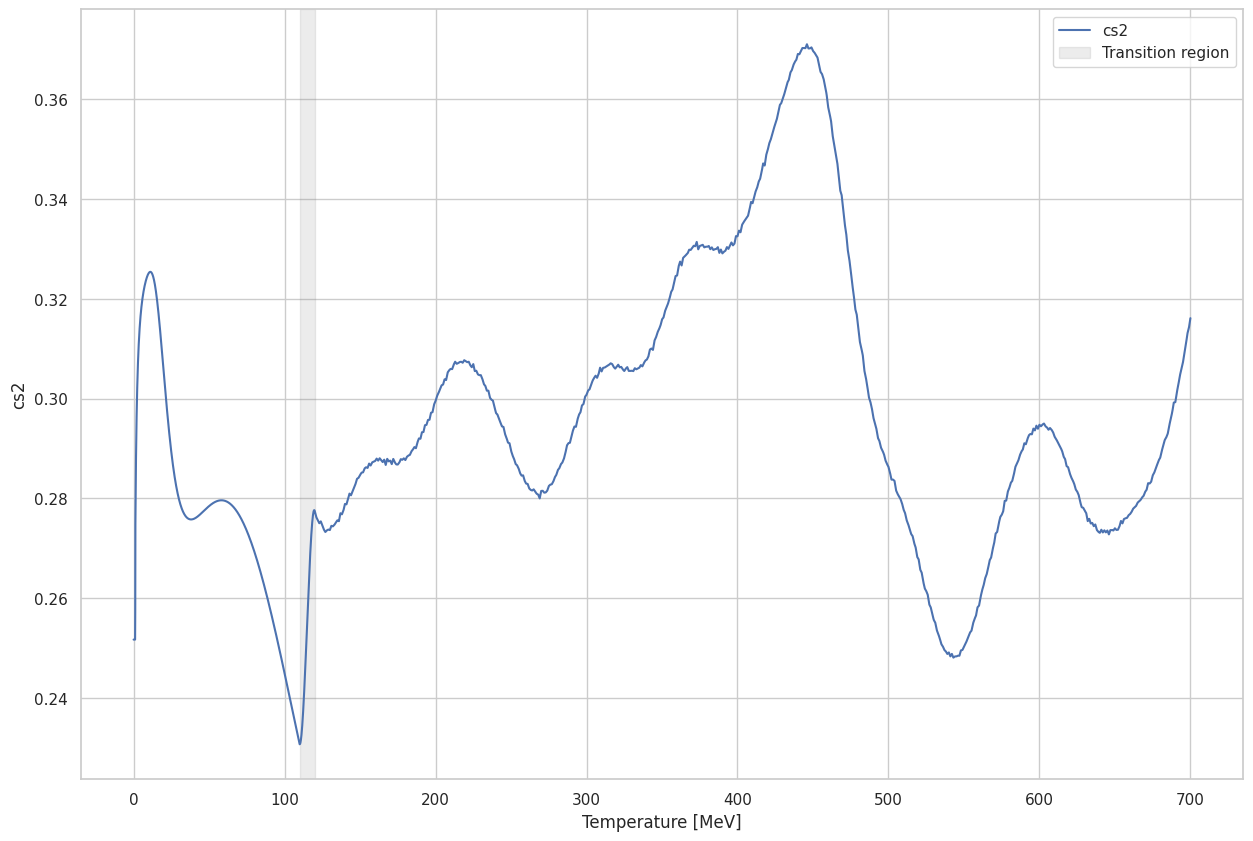

In [209]:
#cs2 plot

cs2_range_unc = np.concatenate([cs2_hrg_to_interp, cs2_interp_unc(T_range_up)])

cs2_extrap_unc = interp1d(T_range_interp, cs2_range_unc, kind='cubic')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_extrap_unc(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_unc.png')
plt.show()


## Taking it as HRG below 150 MeV

In [49]:
#HRG range

T_hrg_to_150 = np.round(np.arange(0, 150+ 00.1, 0.1), 10)

pressure_hrg_vec = P_extrap_hrg(T_hrg_to_150, m_fermions, g_f, m_bosons, g_b)
energy_hrg_vec = e_extrap_hrg(T_hrg_to_150, m_fermions, g_f, m_bosons, g_b)

entropy_hrg_vec =[]
for i in range(0, len(energy_hrg_vec)):
    if i == 0:
        entropy_hrg_vec.append(0)
    else:
        entropy_hrg_vec.append((energy_hrg_vec[i] + pressure_hrg_vec[i])/T_hrg_to_150[i])

In [50]:
pressure_total = np.concatenate([pressure_hrg_vec, P_up[301:5801]])
energy_total = np.concatenate([energy_hrg_vec, e_up[301:5801]])
entropy_total = np.concatenate([entropy_hrg_vec, s_up[301:5801]])

In [55]:
p_hrg_interp = interp1d(T_total, pressure_total, kind='linear')
e_hrg_interp = interp1d(T_total, energy_total, kind='linear')
s_hrg_interp = interp1d(T_total, entropy_total, kind='linear')

In [52]:
# print(energy_hrg_vec[1499], e_up[300])
print(energy_hrg(150, m_fermions, g_f, m_bosons, g_b), e_sw, e_up[300])

1945537282.1988468 1945537282.1988468 1945537282.1988468


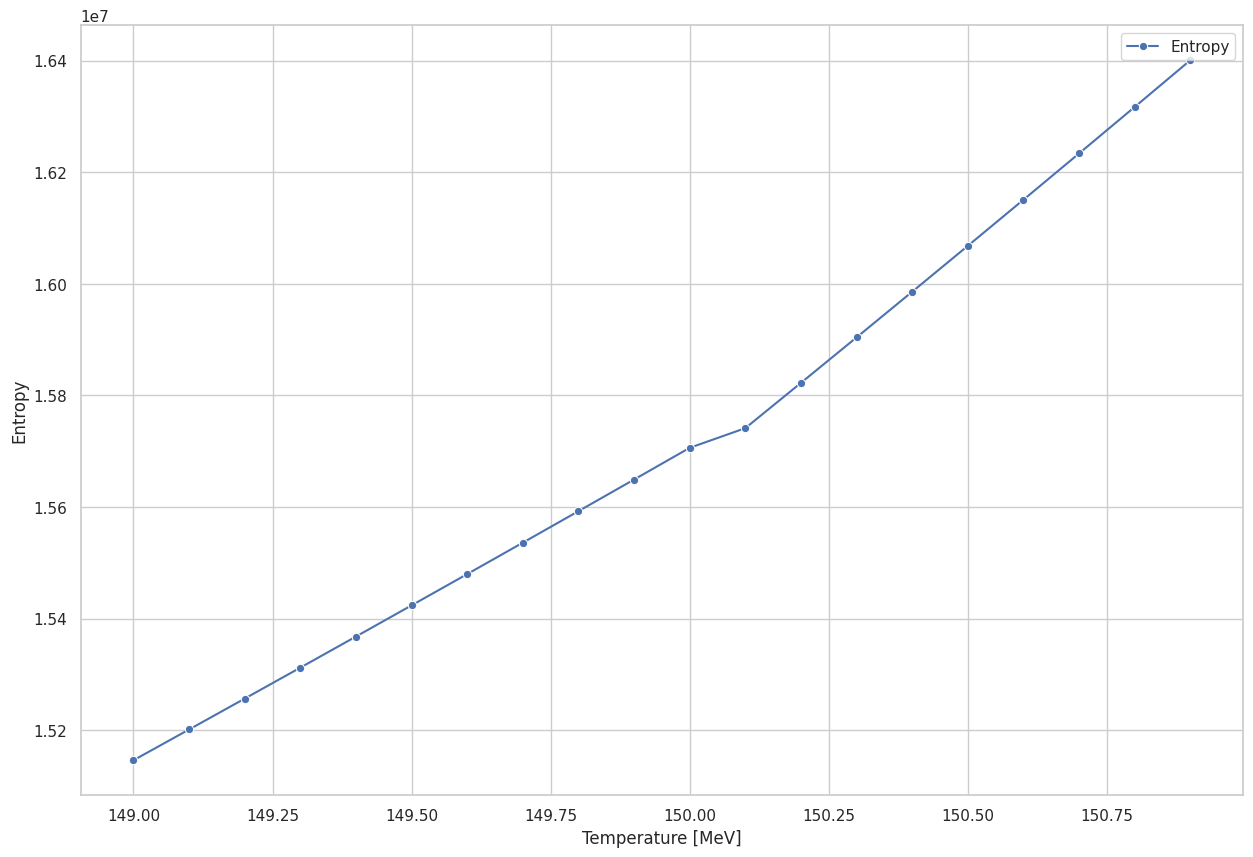

In [53]:
df = pd.DataFrame({'T': T_total[1490:1510], 'pressure': s_hrg_interp(T_total[1490:1510])})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='pressure', label='Entropy', marker='o')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Entropy')
plt.legend()
plt.savefig('./images/s_hrg_150_transition.png')
plt.show()


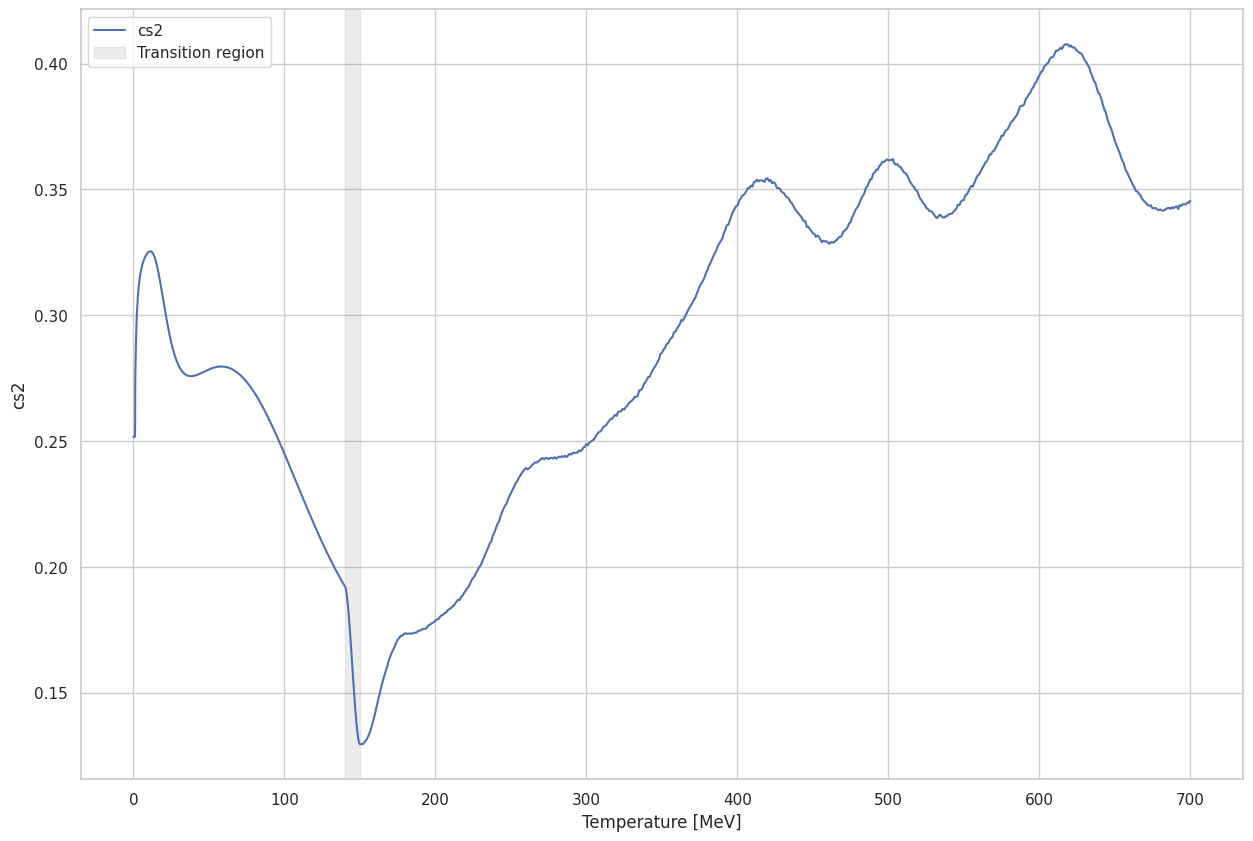

In [210]:
#cs2 plot

dP_dT = np.gradient(pressure_hrg_vec[:1400], T_hrg_to_150[:1400])
de_dT = np.gradient(energy_hrg_vec[:1400], T_hrg_to_150[:1400])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_150 = dP_dT / de_dT

# Fill NaNs with first valid value
cs2_hrg_to_150[np.isnan(cs2_hrg_to_150)] = cs2_hrg_to_150[~np.isnan(cs2_hrg_to_150)][0]

cs2_to_150 = np.concatenate([cs2_hrg_to_150, cs2_interp(T_total[1500:])])

cs2_interp_150 = interp1d(np.concatenate([ T_hrg_to_150[:1400],T_total[1500:] ]), cs2_to_150, kind='cubic')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_interp_150(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(140, 150, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_to_150.png')
plt.show()

/tmp/ipykernel_16473/2680549551.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


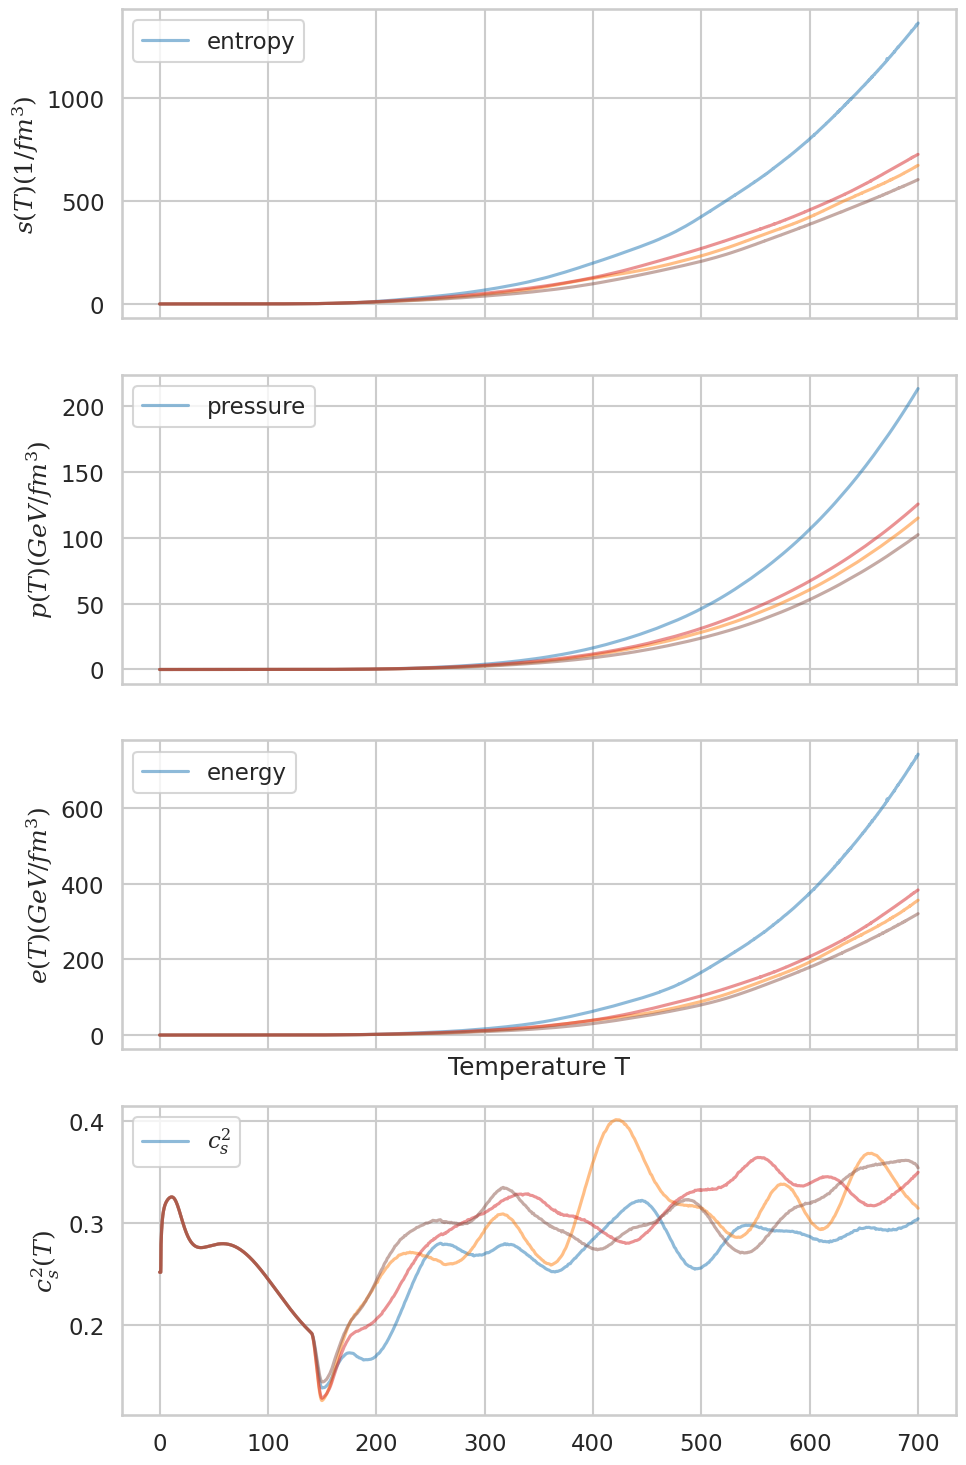

In [211]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    entropy_total_plot = []
    pressure_total_plot = []
    energy_total_plot = []
    cs2_hrg_plot = []
    
    cs2_sample_plot = generate_sample()
    
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)

    e_up_vec = s_up_vec*T_range_up - P_up_vec

    pressure_total_plot = np.concatenate([pressure_hrg_vec, P_up_vec[301:5801]])
    energy_total_plot = np.concatenate([energy_hrg_vec, e_up_vec[301:5801]])
    entropy_total_plot = np.concatenate([entropy_hrg_vec, s_up_vec[301:5801]])
    
    p_hrg_interp_plot = interp1d(T_total, pressure_total_plot, kind='linear')
    e_hrg_interp_plot = interp1d(T_total, energy_total_plot, kind='linear')
    s_hrg_interp_plot = interp1d(T_total, entropy_total_plot, kind='linear')

    cs2_to_150_plot = np.concatenate([cs2_hrg_to_150, cs2_interp_plot(T_total[1500:])])

    cs2_interp_150 = interp1d(np.concatenate([ T_hrg_to_150[:1400],T_total[1500:] ]), cs2_to_150_plot, kind='cubic')

    color = colors[i] 
    axs[0].plot(T_total, s_hrg_interp_plot(T_total)*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total, p_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total, e_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total, cs2_interp_150(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[2].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_hrg_to_150.png')
plt.show()

## For unc gp

In [56]:
pressure_total_unc = np.concatenate([pressure_hrg_vec, P_up_unc[301:5801]])
energy_total_unc = np.concatenate([energy_hrg_vec, e_up_unc[301:5801]])
entropy_total_unc = np.concatenate([entropy_hrg_vec, s_up_unc[301:5801]])

p_hrg_interp_unc = interp1d(T_total, pressure_total_unc, kind='linear')
e_hrg_interp_unc = interp1d(T_total, energy_total_unc, kind='linear')
s_hrg_interp_unc = interp1d(T_total, entropy_total_unc, kind='linear')

/tmp/ipykernel_16473/3972976003.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


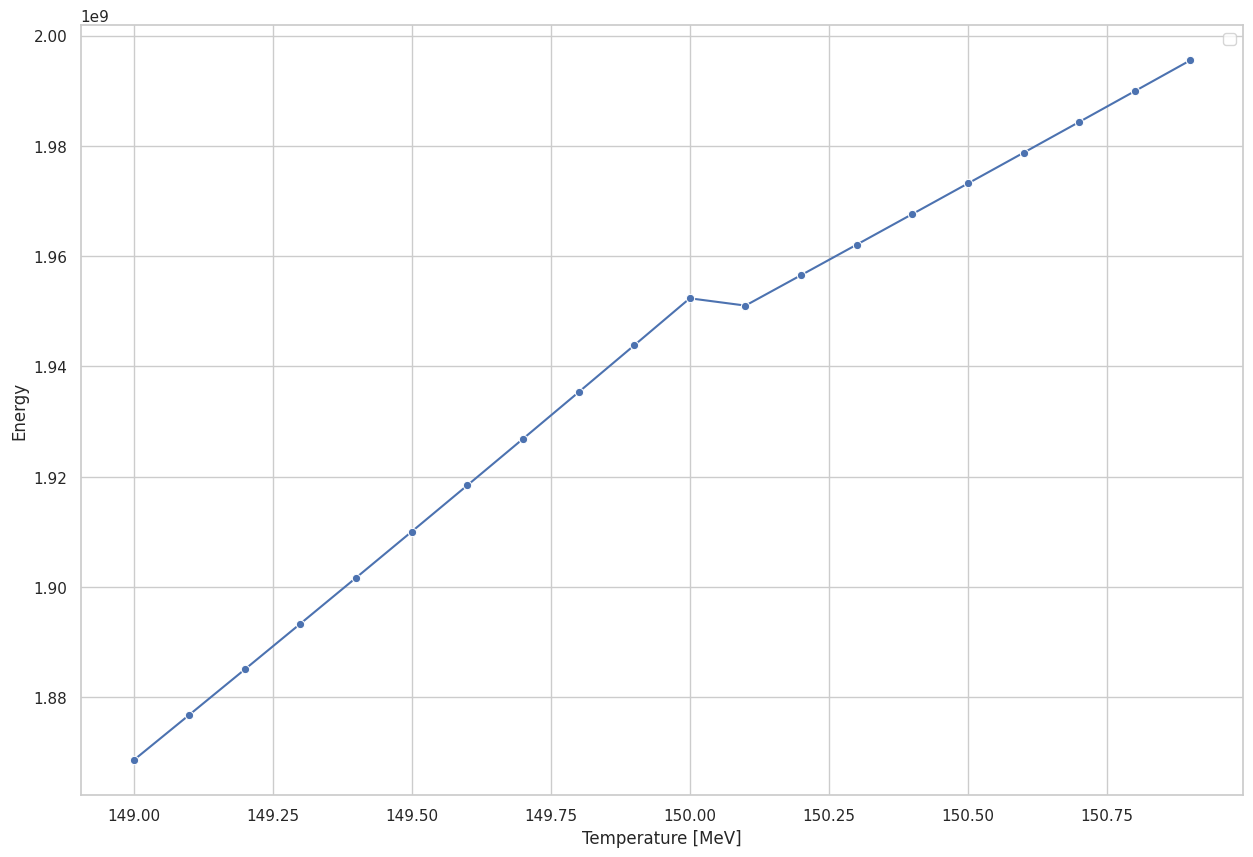

In [57]:
df = pd.DataFrame({'T': T_total[1490:1510], 'pressure': e_hrg_interp_unc(T_total[1490:1510])})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='pressure', marker='o')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Energy')
plt.legend()
plt.savefig('./images/e_unc_hrg_150.png')
plt.show()

In [58]:
with open("./check_files/thermo_check_hrg_150.txt", "w") as f:
    s = s_hrg_interp(T_total)
    p = p_hrg_interp(T_total)
    e = e_hrg_interp(T_total)

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-4:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

Discrepancy at T = 403.20 MeV: e + p = 726335683541.132080, s*T = 726335683541.131958, diff = 1.22e-04
Discrepancy at T = 404.40 MeV: e + p = 734799016317.487061, s*T = 734799016317.487183, diff = 1.22e-04
Discrepancy at T = 405.70 MeV: e + p = 744165776953.708984, s*T = 744165776953.709106, diff = 1.22e-04
Discrepancy at T = 406.70 MeV: e + p = 751286302683.503174, s*T = 751286302683.503052, diff = 1.22e-04
Discrepancy at T = 407.90 MeV: e + p = 760020754474.537842, s*T = 760020754474.537964, diff = 1.22e-04
Discrepancy at T = 408.10 MeV: e + p = 761472529002.078369, s*T = 761472529002.078247, diff = 1.22e-04
Discrepancy at T = 410.60 MeV: e + p = 779185234435.869141, s*T = 779185234435.869019, diff = 1.22e-04
Discrepancy at T = 411.10 MeV: e + p = 782817337101.969238, s*T = 782817337101.969360, diff = 1.22e-04
Discrepancy at T = 411.70 MeV: e + p = 787181328341.178955, s*T = 787181328341.179077, diff = 1.22e-04
Discrepancy at T = 411.80 MeV: e + p = 787930534227.125488, s*T = 7879305

## File 

In [213]:
with open("./data_files/eos_pwr.dat", "w") as f:
    for e, T, p, cs2, s in zip(e_pwr_total, T_total, P_pwr_total, cs2_interp_pwr(T_total), s_pwr_total):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)} \n")

with open("./data_files/eos_weighted.dat", "w") as f:
    s_file = (weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up) +  weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up))/T_total
    for e, T, p, cs2, s in zip(weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up), T_total, weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up), cs2_interp_w(T_total), s_file):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)} \n")

with open("./data_files/eos_hrg_to_150.dat", "w") as f:
    for e, T, p, cs2 in zip(e_hrg_interp(T_total), T_total, p_hrg_interp(T_total), cs2_interp_150(T_total)):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} \n")

with open("./data_files/eos_weighted_unc.dat", "w") as f:
    for e, T, p, cs2 in zip(weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up_unc), T_total, weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up_unc), cs2_extrap_unc(T_total)):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} \n")

""" with open("./data_files/eos_hrg_to_150_unc.dat", "w") as f:
    for e, T, p, cs2 in zip(e_hrg_interp(T_total), T_total, p_hrg_interp(T_total), (T_total)):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} \n") """

""" with open("check.dat", "w") as f:
    for T, s, p, e in zip(T_total, s_total(T_total), P_total(T_total), e_total(T_total)):
              f.write(f"{T} {s*(1/hbarc**3)} {p*MeV4_to_GeV_fm3} {e*MeV4_to_GeV_fm3} \n") """

/tmp/ipykernel_16473/2773263738.py:6: RuntimeWarning: invalid value encountered in divide
  s_file = (weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up) +  weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up))/T_total


' with open("check.dat", "w") as f:\n    for T, s, p, e in zip(T_total, s_total(T_total), P_total(T_total), e_total(T_total)):\n              f.write(f"{T} {s*(1/hbarc**3)} {p*MeV4_to_GeV_fm3} {e*MeV4_to_GeV_fm3} \n") '

In [346]:
with open("./data_files/eos_weighted_edep.dat", "w") as f:
    #s_file = (weighted_total(w_range, T_range_hrg, e_extrap_hrg_vec, e_up) +  weighted_total(w_range, T_range_hrg, P_extrap_hrg_vec, P_up))/T_total
    for e, T, p, cs2, s in zip(e_grid, T_e, interp_P_e(e_grid), interp_cs2_e(e_grid), interp_s_e(e_grid)):
        f.write(f"{e*MeV4_to_GeV_fm3} {T} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)} \n")